In [ ]:
#Importamos las librerias que vamos a utilizar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from xgboost import XGBClassifier

from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline

from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_validate,
    cross_val_predict,
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
    balanced_accuracy_score,
    ConfusionMatrixDisplay,
    silhouette_score,
)

In [56]:
ruta = r"Material/Datasets/ai4i2020_model_ready.csv"
df = pd.read_csv(ruta)

In [57]:
# Mostramos las primeras filas del DataFrame
df.head()


,Type,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Machine_failure,Temperature_difference_K,Angular_speed_rad_s,Mechanical_power_W
0,M,298.1,308.6,1551,42.8,0,0,10.5,162.420340,6951.590560
1,L,298.2,308.7,1408,46.3,3,0,10.5,147.445415,6826.722724
2,L,298.1,308.5,1498,49.4,5,0,10.4,156.870193,7749.387543
3,L,298.2,308.6,1433,39.5,7,0,10.4,150.063409,5927.504659
4,L,298.2,308.7,1408,40.0,9,0,10.5,147.445415,5897.816608


## Planteamiento del problema de Machine Learning (preentrega 2)

# 2. Planteamiento del problema de ML #

## 2.1. Definición del problema y objetivo del modelo

El objetivo de esta etapa es desarrollar y evaluar modelos de Machine Learning supervisado capaces de clasificar si una máquina presenta una condición de falla a partir de sus características físicas y operativas.

Se plantea un problema de **clasificación binaria**, donde la variable objetivo es `Machine_failure`:

- **Clase 0:** no se registra una falla.
- **Clase 1:** se registra una falla.

La pregunta principal que buscamos responder es:

**¿Es posible identificar registros asociados a fallas de maquinaria industrial utilizando las condiciones operativas disponibles y minimizando las falsas alarmas sin dejar de detectar una proporción relevante de fallas reales?**

Debido al fuerte desbalance de clases y al contexto de mantenimiento industrial, no será suficiente maximizar la exactitud (*accuracy*) o el *recall* de manera aislada.

Se buscará un equilibrio entre la detección de fallas y la precisión de las alertas, mediante métricas adecuadas, comparación de algoritmos y evaluación de distintos umbrales de clasificación.

## 2.2. Definición de variables predictoras (X) y variable objetivo (y)

Para desarrollar el modelo de clasificación binaria, definiremos las características que se utilizarán como entrada del algoritmo y la variable que buscamos predecir.

Por convención, utilizaremos:

- **X (features):** conjunto de variables predictoras utilizadas para realizar las predicciones.
- **y (target):** variable objetivo que indica si se registra una falla en la máquina.

### Variable objetivo

La variable objetivo será `Machine_failure`, que toma dos valores:

- **0:** no se registra una falla.
- **1:** se registra una falla.

### Variables predictoras originales

Inicialmente se considerarán las siguientes características operativas:

- `Type`: categoría de calidad del producto (L, M o H).
- `Air_temperature_K`: temperatura del aire.
- `Process_temperature_K`: temperatura del proceso.
- `Rotational_speed_rpm`: velocidad de rotación.
- `Torque_Nm`: torque.
- `Tool_wear_min`: desgaste acumulado de la herramienta.

### Características derivadas mediante Feature Engineering

A partir del análisis exploratorio realizado en la sección 1.7, se evaluará la incorporación de dos características derivadas:

- `Temperature_difference_K`: diferencia entre la temperatura del proceso y la temperatura del aire.
- `Mechanical_power_W`: potencia mecánica rotacional aproximada, calculada a partir del torque y la velocidad angular.

Adicionalmente, se calculó `Angular_speed_rad_s` como variable intermedia para obtener la potencia mecánica. No se incorporará como predictor independiente en la configuración inicial, dado que es una transformación lineal de `Rotational_speed_rpm`.

Estas características permitirán representar relaciones físicas entre las condiciones operativas. Sin embargo, su utilidad predictiva deberá comprobarse mediante experimentos comparativos.

Posteriormente se realizará un estudio de ablación para comparar el desempeño de los modelos entrenados con variables originales frente a modelos que también incorporen las características derivadas.

### Variables excluidas

Se excluirán las siguientes columnas:

**Identificadores:**

- `UDI`
- `Product_ID`

Estos campos identifican registros o productos y no representan directamente mediciones físicas operativas.

**Etiquetas específicas de falla:**

- `TWF`
- `HDF`
- `PWF`
- `OSF`
- `RNF`

Estas columnas describen modos de falla y no deben utilizarse como predictores de `Machine_failure`, ya que contienen información directamente relacionada con el resultado que buscamos predecir y podrían provocar fuga de información (*data leakage*).

### Consideraciones para el modelado

La selección inicial de características estará fundamentada en las variables operativas disponibles y en las hipótesis exploratorias desarrolladas durante el EDA.

Las transformaciones necesarias, como la codificación de variables categóricas y el escalado de variables numéricas, se incorporarán dentro de un pipeline de preprocesamiento.

Finalmente, la utilidad de las variables derivadas se comprobará mediante experimentos comparativos, evitando seleccionar características únicamente a partir de correlaciones o visualizaciones.

## 2.3. Limitaciones del problema

Antes de desarrollar los modelos de clasificación, es importante reconocer las principales limitaciones del dataset.

### 1. Desbalance de clases

El dataset presenta un fuerte desbalance entre las clases: el 96,61 % de los registros corresponde a máquinas sin falla, mientras que únicamente el 3,39 % presenta una falla.

Esto representa un desafío para el entrenamiento y la evaluación, ya que un modelo podría alcanzar una exactitud elevada prediciendo mayoritariamente la clase 0, sin detectar adecuadamente los registros con falla.

Por este motivo, utilizaremos métricas como Precision, Recall, F1-score y Average Precision, complementadas con matrices de confusión y curvas Precision-Recall.

### 2. Fallas aleatorias (RNF)

El dataset incorpora una categoría denominada `RNF` (*Random Failure*), generada aleatoriamente y sin una relación física sistemática esperable con las variables operativas disponibles.

Por lo tanto, algunas fallas no podrán explicarse adecuadamente mediante las características utilizadas.

Además, durante el EDA se identificaron discrepancias entre las etiquetas de falla general y los indicadores específicos, lo que representa una limitación adicional para la interpretación de los resultados.

### 3. Costos operativos de los errores de clasificación

En mantenimiento industrial, los errores de clasificación pueden tener consecuencias diferentes:

- **Falsos positivos:** alertas emitidas cuando no existe una falla registrada, que podrían provocar inspecciones innecesarias.
- **Falsos negativos:** fallas que el modelo no detecta, con posibles consecuencias operativas y económicas.

Por este motivo, no será suficiente maximizar únicamente el Recall. Buscaremos un equilibrio entre detección de fallas y precisión de las alertas.

Posteriormente incorporaremos un análisis de costos simulados para comparar diferentes estrategias de decisión.

### Implicancias para el proyecto

Estas limitaciones serán consideradas durante la selección de variables, el entrenamiento, el tratamiento del desbalance y la evaluación de los algoritmos.

El objetivo será desarrollar un prototipo de clasificación técnicamente fundamentado, reproducible e interpretable, reconociendo sus alcances y evitando presentar sus resultados como evidencia suficiente para una implementación industrial directa.

# 3. Preprocesamiento y preparación de datos

## 3.1. Construcción de las variables predictoras (X) y la variable objetivo (y)

En esta etapa se prepararán los conjuntos de características que utilizaremos durante el entrenamiento y la evaluación de los algoritmos de clasificación.

Se construirán dos matrices de variables predictoras:

- **X_original:** contiene las características operativas originales del dataset.
- **X:** contiene las características originales junto con las variables derivadas mediante ingeniería de características.

Esta separación permitirá estudiar posteriormente si las nuevas características aportan mejoras reales en el desempeño de los modelos.

La variable objetivo será `Machine_failure`, representada mediante `y`.

No se incluirán identificadores ni etiquetas específicas de falla entre las características predictoras, para evitar incorporar información inadecuada o directamente relacionada con el resultado que buscamos predecir.

In [58]:
# 3.1 - Selección de características y variable objetivo

variables_categoricas = ["Type"]

# Variables numéricas originales
variables_numericas_originales = [
    "Air_temperature_K",
    "Process_temperature_K",
    "Rotational_speed_rpm",
    "Torque_Nm",
    "Tool_wear_min"
]

# Variables creadas mediante Feature Engineering
variables_derivadas = [
    "Temperature_difference_K",
    "Mechanical_power_W"
]

# Variables numéricas del conjunto ampliado
variables_numericas = (
    variables_numericas_originales + variables_derivadas
)

# Matriz con variables originales
X_original = df[
    variables_categoricas + variables_numericas_originales
].copy()

# Matriz con variables originales y derivadas
X = df[
    variables_categoricas + variables_numericas
].copy()

# Variable objetivo
y = df["Machine_failure"].copy()

# Verificaciones
print("Dimensiones de X_original:", X_original.shape)
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

print("\nVariables utilizadas en X:")
print(X.columns.tolist())

print("\nDistribución del target:")
print(y.value_counts())

Dimensiones de X_original: (10000, 6)
Dimensiones de X: (10000, 8)
Dimensiones de y: (10000,)

Variables utilizadas en X:
['Type', 'Air_temperature_K', 'Process_temperature_K', 'Rotational_speed_rpm', 'Torque_Nm', 'Tool_wear_min', 'Temperature_difference_K', 'Mechanical_power_W']

Distribución del target:
Machine_failure
0    9661
1     339
Name: count, dtype: int64


## 3.2. Preprocesamiento de variables con ColumnTransformer

Antes de entrenar los modelos de Machine Learning, es necesario preparar las características de acuerdo con su naturaleza.

Vamos a usar las siguientes técnicas:

- **OneHotEncoder:** transforma la variable categórica `Type` en columnas binarias, evitando asignar un orden numérico artificial a sus categorías.
- **StandardScaler:** estandariza las variables numéricas, centrándolas en una media de cero y escalándolas a una desviación estándar de uno, según los parámetros aprendidos durante el entrenamiento.

La estandarización es especialmente importante para algoritmos sensibles a la escala, como la regresión logística, y para métodos basados en distancias.

Se definirán dos configuraciones de preprocesamiento: una para las características originales y otra para el conjunto ampliado que incorpora las variables derivadas.

Estas transformaciones se integrarán posteriormente en los pipelines de entrenamiento para evitar fuga de información (*data leakage*). Los parámetros del escalado se aprenderán exclusivamente a partir de los datos de entrenamiento de cada partición de validación.

Finalmente, el tratamiento del desbalance de clases se analizará por separado, comparando alternativas como SMOTE y pesos de clase.

In [27]:
# 3.2 - Preprocesamiento de variables

# Preprocesamiento con variables originales
preprocesamiento_original = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            variables_categoricas
        ),
        (
            "numericas",
            StandardScaler(),
            variables_numericas_originales
        )
    ],
    remainder="drop"
)

# Preprocesamiento con variables originales y derivadas
preprocesamiento = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            variables_categoricas
        ),
        (
            "numericas",
            StandardScaler(),
            variables_numericas
        )
    ],
    remainder="drop"
)

print("Variables categóricas:", variables_categoricas)
print("Variables numéricas originales:", variables_numericas_originales)
print("Variables numéricas ampliadas:", variables_numericas)

print("\nPreprocesamiento original:")
print(preprocesamiento_original)

print("\nPreprocesamiento ampliado:")
print(preprocesamiento)

Variables categóricas: ['Type']
Variables numéricas originales: ['Air_temperature_K', 'Process_temperature_K', 'Rotational_speed_rpm', 'Torque_Nm', 'Tool_wear_min']
Variables numéricas ampliadas: ['Air_temperature_K', 'Process_temperature_K', 'Rotational_speed_rpm', 'Torque_Nm', 'Tool_wear_min', 'Temperature_difference_K', 'Mechanical_power_W']

Preprocesamiento original:
ColumnTransformer(transformers=[('categoricas',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['Type']),
                                ('numericas', StandardScaler(),
                                 ['Air_temperature_K', 'Process_temperature_K',
                                  'Rotational_speed_rpm', 'Torque_Nm',
                                  'Tool_wear_min'])])

Preprocesamiento ampliado:
ColumnTransformer(transformers=[('categoricas',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['Type'])

## 3.3. División de datos para entrenamiento y evaluación

Para evaluar correctamente la capacidad de generalización de los modelos, dividiremos el conjunto de datos en dos partes:

- **Conjunto de desarrollo (80 %):** se utilizará para entrenar modelos, optimizar hiperparámetros y realizar validación cruzada.
- **Conjunto de prueba (20 %):** se reservará exclusivamente para la evaluación final del modelo seleccionado.

La división se realizará de manera estratificada, conservando aproximadamente la proporción de registros con y sin falla en ambos conjuntos.

Debido al desbalance de clases del dataset, esta estrategia permite disponer de ejemplos de la clase minoritaria tanto para el entrenamiento como para la evaluación.

Durante el desarrollo utilizaremos validación cruzada estratificada para comparar diferentes algoritmos y estrategias de balanceo.

También seleccionaremos el umbral de clasificación utilizando únicamente datos del conjunto de desarrollo, evitando que las decisiones del modelado dependan de los resultados del conjunto de prueba.

Las transformaciones de preprocesamiento se ajustarán dentro de los pipelines de entrenamiento, evitando utilizar información estadística de los datos de prueba.

In [28]:
# División estratificada: 80 % desarrollo, 20 % prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Conjunto original con los mismos registros
X_original_train = X_original.loc[X_train.index].copy()
X_original_test = X_original.loc[X_test.index].copy()

# Verificación
print("Desarrollo:", X_train.shape)
print("Test:", X_test.shape)

print("\nDistribución de clases en desarrollo:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

print("\nDistribución de clases en test:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True) * 100)

# Verificar que no compartan registros
assert set(X_train.index).isdisjoint(set(X_test.index))

Desarrollo: (8000, 8)
Test: (2000, 8)

Distribución de clases en desarrollo:
Machine_failure
0    7729
1     271
Name: count, dtype: int64
Machine_failure
0    96.6125
1     3.3875
Name: proportion, dtype: float64

Distribución de clases en test:
Machine_failure
0    1932
1      68
Name: count, dtype: int64
Machine_failure
0    96.6
1     3.4
Name: proportion, dtype: float64


### Conclusiones de la división de datos 

Realizamos una división estratificada del dataset, asignando el 80 % de los registros al conjunto de desarrollo (8.000 observaciones) y el 20 % al conjunto de prueba (2.000 observaciones).

El conjunto de desarrollo contiene 7.729 registros sin falla y 271 con falla, mientras que el conjunto de prueba contiene 1.932 registros sin falla y 68 con falla.

La proporción de registros con falla se mantuvo prácticamente constante en ambos conjuntos (3,39 % y 3,40 %, respectivamente), confirmando que la estratificación preservó adecuadamente el desbalance original.

Esta división permitirá realizar el entrenamiento y la optimización de los modelos utilizando exclusivamente el conjunto de desarrollo, reservando el test para la evaluación final.

Además, se conservaron las mismas observaciones para los conjuntos de características originales y ampliadas, lo que permitirá comparar posteriormente el aporte de la ingeniería de características bajo condiciones equivalentes.

## 3.4. Verificación del preprocesamiento

Antes de iniciar el entrenamiento de los modelos, verificaremos que las configuraciones de `ColumnTransformer` sean compatibles con los conjuntos de características definidos.

Se comprobará que:

- La variable categórica `Type` se codifique correctamente mediante `OneHotEncoder`.
- Las variables numéricas se estandaricen mediante `StandardScaler`.
- Los conjuntos original y ampliado produzcan la cantidad esperada de características transformadas.
- No existan valores faltantes generados por las transformaciones.

La verificación se realizará utilizando exclusivamente el conjunto de desarrollo, sin ajustar los transformadores sobre los datos de prueba.

Los transformadores utilizados en esta prueba serán copias independientes. Durante el entrenamiento definitivo, las transformaciones se integrarán dentro de los pipelines para que sus parámetros se aprendan únicamente a partir de los datos de entrenamiento correspondientes a cada partición de validación.

In [29]:
# Copias independientes para verificar el preprocesamiento
pre_original_check = clone(preprocesamiento_original)
pre_ampliado_check = clone(preprocesamiento)

# Ajustar únicamente con datos de desarrollo
X_original_transformado = pre_original_check.fit_transform(
    X_original_train
)

X_ampliado_transformado = pre_ampliado_check.fit_transform(
    X_train
)

# Convertir a matrices densas si fuera necesario
if hasattr(X_original_transformado, "toarray"):
    X_original_transformado = X_original_transformado.toarray()

if hasattr(X_ampliado_transformado, "toarray"):
    X_ampliado_transformado = X_ampliado_transformado.toarray()

print("Conjunto original transformado:",
      X_original_transformado.shape)

print("Conjunto ampliado transformado:",
      X_ampliado_transformado.shape)

print("\nValores no finitos (original):",
      (~np.isfinite(X_original_transformado)).sum())

print("Valores no finitos (ampliado):",
      (~np.isfinite(X_ampliado_transformado)).sum())

# Comprobaciones automáticas
assert X_original_transformado.shape[0] == len(X_original_train)
assert X_ampliado_transformado.shape[0] == len(X_train)

assert np.isfinite(X_original_transformado).all()
assert np.isfinite(X_ampliado_transformado).all()

print("\nVerificaciones completadas correctamente.")

Conjunto original transformado: (8000, 8)
Conjunto ampliado transformado: (8000, 10)

Valores no finitos (original): 0
Valores no finitos (ampliado): 0

Verificaciones completadas correctamente.


### 3.4.1. Conclusiones de la verificación del preprocesamiento

Se verificó el funcionamiento de los dos `ColumnTransformer` definidos para los conjuntos de características originales y ampliadas.

El conjunto original produjo una matriz transformada de 8.000 registros y 8 características, mientras que el conjunto ampliado produjo una matriz de 8.000 registros y 10 características.

Esta diferencia se debe a la codificación de las tres categorías de `Type` mediante `OneHotEncoder` y a la incorporación de dos variables derivadas en el segundo conjunto.

No se identificaron valores no finitos y todas las comprobaciones automáticas se ejecutaron correctamente.

Los transformadores se ajustaron exclusivamente con datos del conjunto de desarrollo y mediante copias independientes, sin utilizar las observaciones reservadas para test.

**Implicancias para el modelado:** ambas configuraciones de preprocesamiento están preparadas para incorporarse a los pipelines de Machine Learning. Esto permitirá comparar posteriormente el desempeño de los modelos con y sin características derivadas, manteniendo las mismas particiones de datos.

Durante la validación cruzada, cada transformador deberá ajustarse únicamente con los registros de entrenamiento de cada partición, evitando fuga de información.

# 4. Aprendizaje supervisado y entrenamiento de modelos

## 4.1. Estrategias para el tratamiento del desbalance de clases

El dataset presenta un desbalance considerable entre las clases: solamente el 3,39 % de los registros corresponde a máquinas con falla.

Se implementó SMOTE para generar observaciones sintéticas de la clase minoritaria.

Sin embargo, la evaluación mostró que la combinación de SMOTE con una optimización basada exclusivamente en *Recall* produjo una cantidad elevada de falsas alarmas.

Para mejorar este resultado, compararemos tres estrategias:

1. **Sin balanceo:** entrenar los modelos con la distribución original de las clases.
2. **Ponderación de clases:** asignar mayor importancia a los errores cometidos sobre la clase minoritaria mediante parámetros como `class_weight` o `scale_pos_weight`, según el algoritmo.
3. **Sobremuestreo mediante SMOTE:** generar observaciones sintéticas de la clase minoritaria exclusivamente durante el entrenamiento.

La utilización de SMOTE con variables categóricas requiere especial atención. Se evaluará un procedimiento adecuado para evitar generar valores sintéticos que no correspondan a categorías válidas.

### Criterios de comparación

No vamos a seleccionar una estrategia únicamente por maximizar el *Recall*.

Se utilizará **Average Precision** como métrica principal para comparar la capacidad de los modelos de ordenar los registros según su riesgo de falla, complementándola con Precision, Recall, F1-score y matrices de confusión.

Posteriormente se analizarán diferentes umbrales de clasificación para encontrar un equilibrio entre fallas detectadas y falsas alarmas.

Todas las comparaciones se realizarán mediante validación cruzada sobre el conjunto de desarrollo, manteniendo reservado el conjunto de prueba para la evaluación final.

## 4.2. Modelo de referencia: Dummy Classifier

Antes de entrenar algoritmos más complejos, estableceremos un modelo de referencia (*baseline*) mediante `DummyClassifier`.

Este algoritmo no aprende relaciones entre las variables predictoras y la variable objetivo. En su lugar, realiza predicciones utilizando una estrategia simple.

Utilizaremos `strategy="prior"`, que predice siempre la clase mayoritaria y asigna probabilidades de acuerdo con las proporciones observadas durante el entrenamiento.

Debido al desbalance del dataset, este clasificador predecirá que las máquinas no presentan fallas en todos los registros.

El objetivo es demostrar por qué una exactitud elevada no necesariamente representa un buen desempeño en problemas con clases desbalanceadas.

Para evaluar el modelo utilizaremos validación cruzada estratificada de cinco particiones sobre el conjunto de desarrollo, manteniendo reservado el conjunto de prueba para la evaluación final.

Sus resultados servirán como referencia para determinar si los algoritmos posteriores aportan capacidad predictiva real.

In [30]:
# Validación cruzada estratificada
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Modelo de referencia
modelo_dummy = DummyClassifier(
    strategy="prior"
)

# Métricas para evaluar el baseline
metricas = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "average_precision": "average_precision",
    "f1": "f1"
}

# Evaluación exclusivamente sobre el conjunto de desarrollo
resultados_dummy = cross_validate(
    modelo_dummy,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas,
    n_jobs=-1
)

# Resumen de resultados
tabla_dummy = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Balanced Accuracy",
        "Average Precision",
        "F1-score"
    ],
    "Media CV": [
        resultados_dummy["test_accuracy"].mean(),
        resultados_dummy["test_balanced_accuracy"].mean(),
        resultados_dummy["test_average_precision"].mean(),
        resultados_dummy["test_f1"].mean()
    ],
    "Desviación estándar": [
        resultados_dummy["test_accuracy"].std(),
        resultados_dummy["test_balanced_accuracy"].std(),
        resultados_dummy["test_average_precision"].std(),
        resultados_dummy["test_f1"].std()
    ]
})

display(tabla_dummy)

,Métrica,Media CV,Desviación estándar
0,Accuracy,0.966125,0.00025
1,Balanced Accuracy,0.500000,0.00000
2,Average Precision,0.033875,0.00025
3,F1-score,0.000000,0.00000


### 4.2.1. Conclusiones del modelo de referencia

Se evaluó un modelo de referencia mediante `DummyClassifier`, utilizando la estrategia `prior` y validación cruzada estratificada de cinco particiones sobre el conjunto de desarrollo.

El modelo obtuvo una exactitud promedio del **96,61 %**, pero una Balanced Accuracy del **50 %** y un F1-score igual a **0**.

Estos resultados se explican porque el clasificador predice siempre la clase mayoritaria, sin identificar ningún registro con falla.

Por su parte, el Average Precision obtenido fue aproximadamente **0,0339**, equivalente a la prevalencia de la clase minoritaria.

Este experimento demuestra que una exactitud elevada no garantiza un buen desempeño en problemas de clasificación desbalanceada.

**Implicancias para el proyecto:** los modelos posteriores deberán superar este rendimiento de referencia, especialmente en Average Precision y F1-score, demostrando una capacidad real para distinguir registros con y sin falla.

Además, deberán evaluarse los compromisos entre fallas detectadas y falsas alarmas, considerando las necesidades de una posible aplicación industrial.

## 4.3. Regresión logística

La regresión logística es un algoritmo de aprendizaje supervisado utilizado para problemas de clasificación. En nuestro proyecto, permitirá estimar la probabilidad de que un registro corresponda a una máquina con falla a partir de sus características operativas.

Se utilizará como primer modelo predictivo, debido a su relativa simplicidad e interpretabilidad.

Dado el fuerte desbalance de clases, evaluaremos diferentes estrategias de entrenamiento para determinar cómo afectan la detección de fallas y la cantidad de falsas alarmas.

### 4.3.1. Modelo inicial sin balanceo

Comenzaremos entrenando una regresión logística sin aplicar técnicas de sobremuestreo ni ponderación de clases.

El objetivo es establecer un punto de comparación para determinar si las estrategias de balanceo mejoran efectivamente el desempeño.

Utilizaremos las características originales y derivadas, aplicando la codificación y estandarización correspondientes dentro de un pipeline.

El rendimiento se evaluará mediante validación cruzada estratificada de cinco particiones sobre el conjunto de desarrollo.

Se utilizará Average Precision como métrica principal para evaluar la capacidad del modelo de distinguir y ordenar registros según su probabilidad estimada de falla. También se calcularán Precision, Recall, F1-score y Balanced Accuracy utilizando el umbral predeterminado de clasificación.

Los resultados servirán como referencia para las siguientes estrategias de entrenamiento.

In [31]:
# Modelo inicial sin balanceo
pipeline_logistica_base = Pipeline([
    ("preprocesamiento", clone(preprocesamiento)),
    ("modelo", LogisticRegression(
        max_iter=2000,
        class_weight=None,
        random_state=42
    ))
])

# Métricas de evaluación
metricas_logistica = {
    "average_precision": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "balanced_accuracy": "balanced_accuracy"
}

# Validación cruzada sobre el conjunto de desarrollo
resultados_logistica_base = cross_validate(
    pipeline_logistica_base,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas_logistica,
    n_jobs=-1
)

# Resumen
tabla_logistica_base = pd.DataFrame({
    "Métrica": list(metricas_logistica.keys()),
    "Media CV": [
        resultados_logistica_base[f"test_{metrica}"].mean()
        for metrica in metricas_logistica
    ],
    "Desviación estándar": [
        resultados_logistica_base[f"test_{metrica}"].std()
        for metrica in metricas_logistica
    ]
})

display(tabla_logistica_base)

,Métrica,Media CV,Desviación estándar
0,average_precision,0.502745,0.028714
1,precision,0.771338,0.084829
2,recall,0.243636,0.030273
3,f1,0.369393,0.040381
4,balanced_accuracy,0.620524,0.015273


Estos resultados muestran que el modelo presenta una elevada precisión en las alertas emitidas, pero una capacidad limitada para detectar la totalidad de las fallas.

En un contexto de mantenimiento industrial, esta situación representa una limitación importante, ya que una proporción considerable de los eventos de falla no sería identificada.

**Implicancias para los siguientes experimentos:** se evaluarán estrategias de balanceo, comenzando por la ponderación de clases y posteriormente el sobremuestreo, para determinar si permiten mejorar la detección de fallas sin incrementar excesivamente las falsas alarmas.

La comparación definitiva deberá realizarse utilizando el mismo procedimiento de validación y considerando conjuntamente Precision, Recall, F1-score y Average Precision.

### 4.3.2. Regresión logística con ponderación de clases

En este experimento evaluaremos el efecto de utilizar `class_weight="balanced"` en la regresión logística.

Este parámetro asigna automáticamente pesos inversamente proporcionales a la frecuencia de las clases, otorgando mayor importancia a los errores cometidos sobre la clase minoritaria.

A diferencia de SMOTE, esta estrategia no genera observaciones sintéticas, sino que modifica la función de optimización del algoritmo.

El objetivo es investigar si la ponderación permite aumentar el recall respecto del modelo sin balanceo, manteniendo una precisión aceptable.

Se utilizarán las mismas características, el mismo preprocesamiento y las mismas particiones de validación cruzada, de manera que las diferencias observadas puedan atribuirse principalmente a la estrategia de ponderación.

In [32]:
# 4.3.2 - Regresión logística con pesos de clase

pipeline_logistica_balanceada = Pipeline([
    ("preprocesamiento", clone(preprocesamiento)),
    ("modelo", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

resultados_logistica_balanceada = cross_validate(
    pipeline_logistica_balanceada,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas_logistica,
    n_jobs=-1
)

tabla_logistica_balanceada = pd.DataFrame({
    "Métrica": list(metricas_logistica.keys()),
    "Media CV": [
        resultados_logistica_balanceada[f"test_{metrica}"].mean()
        for metrica in metricas_logistica
    ],
    "Desviación estándar": [
        resultados_logistica_balanceada[f"test_{metrica}"].std()
        for metrica in metricas_logistica
    ]
})

display(tabla_logistica_balanceada)

,Métrica,Media CV,Desviación estándar
0,average_precision,0.483514,0.025424
1,precision,0.164727,0.012008
2,recall,0.823098,0.048032
3,f1,0.274356,0.018123
4,balanced_accuracy,0.838124,0.023712


Se evaluó una regresión logística utilizando `class_weight="balanced"`, con el objetivo de aumentar la importancia de la clase minoritaria durante el entrenamiento.

El modelo obtuvo un recall promedio del **82,31 %**, considerablemente superior al 24,36 % alcanzado por la regresión logística sin balanceo.

Sin embargo, esta mejora estuvo acompañada de una reducción importante de la precisión, que pasó del 77,13 % al 16,47 %. Esto indica que el modelo detecta una mayor proporción de fallas, pero emite numerosas alertas incorrectas.

El F1-score disminuyó de 0,3694 a 0,2744, mientras que Average Precision pasó de 0,5027 a 0,4835.

Estos resultados evidencian que la ponderación de clases no garantiza automáticamente una mejora global del desempeño.

**Implicancias para el proyecto:** la selección del modelo no debe basarse exclusivamente en recall, ya que maximizar la detección de fallas puede generar una cantidad operativamente elevada de falsas alarmas.

Por lo tanto, resulta necesario comparar distintas estrategias de entrenamiento y, posteriormente, optimizar el umbral de clasificación para encontrar un equilibrio más adecuado entre precisión y sensibilidad.

Los resultados corresponden a promedios de validación cruzada sobre el conjunto de desarrollo y no constituyen una evaluación final sobre test.

### 4.3.3. Regresión logística con sobremuestreo mediante SMOTENC

En este experimento evaluaremos el efecto del sobremuestreo de la clase minoritaria mediante **SMOTENC (Synthetic Minority Over-sampling Technique for Nominal and Continuous)**.

A diferencia de SMOTE convencional, SMOTENC está diseñado para conjuntos de datos que contienen tanto variables numéricas como categóricas.

En nuestro caso, la variable `Type` es categórica, mientras que las temperaturas, la velocidad, el torque, el desgaste y las características derivadas son numéricas.

In [33]:
# 4.3.3 - Regresión logística con SMOTENC


# Paso 1: escalar las variables numéricas
# y conservar Type como categórica
preprocesamiento_antes_smote = ColumnTransformer(
    transformers=[
        ("categorica", "passthrough", variables_categoricas),
        ("numericas", StandardScaler(), variables_numericas)
    ],
    sparse_threshold=0
)

# Paso 2: SMOTENC
# Type queda en la primera posición (índice 0)
smotenc = SMOTENC(
    categorical_features=[0],
    random_state=42,
    k_neighbors=5
)

# Paso 3: codificar la variable categórica
# Las numéricas ya están estandarizadas
preprocesamiento_despues_smote = ColumnTransformer(
    transformers=[
        ("categorica", OneHotEncoder(handle_unknown="ignore"), [0]),
        ("numericas", "passthrough", list(range(1, 8)))
    ]
)

# Pipeline completo
pipeline_logistica_smotenc = Pipeline([
    ("preprocesamiento_inicial", preprocesamiento_antes_smote),
    ("smotenc", smotenc),
    ("codificacion", preprocesamiento_despues_smote),
    ("modelo", LogisticRegression(
        max_iter=2000,
        class_weight=None,
        random_state=42
    ))
])

# Validación cruzada estratificada
resultados_logistica_smotenc = cross_validate(
    pipeline_logistica_smotenc,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas_logistica,
    n_jobs=-1
)

# Tabla de resultados
tabla_logistica_smotenc = pd.DataFrame({
    "Métrica": list(metricas_logistica.keys()),
    "Media CV": [
        resultados_logistica_smotenc[f"test_{metrica}"].mean()
        for metrica in metricas_logistica
    ],
    "Desviación estándar": [
        resultados_logistica_smotenc[f"test_{metrica}"].std()
        for metrica in metricas_logistica
    ]
})

display(tabla_logistica_smotenc)

,Métrica,Media CV,Desviación estándar
0,average_precision,0.465934,0.035335
1,precision,0.171964,0.006014
2,recall,0.800808,0.037327
3,f1,0.282903,0.006819
4,balanced_accuracy,0.832607,0.013770


### 4.3.4. Comparación de estrategias de entrenamiento

Tras evaluar tres configuraciones de regresión logística, compararemos sus resultados para analizar el efecto de las diferentes técnicas de tratamiento del desbalance.

Las configuraciones evaluadas fueron:

1. Regresión logística sin balanceo.
2. Regresión logística con ponderación de clases.
3. Regresión logística con sobremuestreo mediante SMOTENC.

Los tres experimentos utilizaron las mismas características predictoras, las mismas particiones de validación cruzada y los mismos hiperparámetros principales del clasificador.

La comparación permitirá determinar qué estrategia ofrece mejores resultados en Average Precision, Precision, Recall y F1-score, considerando especialmente el compromiso entre detección de fallas y falsas alarmas.

Los resultados corresponden a validación cruzada sobre el conjunto de desarrollo. La selección definitiva del modelo y del umbral de clasificación se realizará posteriormente, sin utilizar el conjunto de prueba para tomar estas decisiones.

In [34]:
# 4.3.4 - Comparación de estrategias de regresión logística

resultados_comparacion = {
    "Sin balanceo": resultados_logistica_base,
    "Pesos de clase": resultados_logistica_balanceada,
    "SMOTENC": resultados_logistica_smotenc
}

metricas_comparacion = [
    "average_precision",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy"
]

filas = []

for nombre, resultados in resultados_comparacion.items():
    fila = {"Estrategia": nombre}

    for metrica in metricas_comparacion:
        fila[metrica] = resultados[f"test_{metrica}"].mean()

    filas.append(fila)

tabla_comparacion_logistica = pd.DataFrame(filas)

display(tabla_comparacion_logistica.round(4))

,Estrategia,average_precision,precision,recall,f1,balanced_accuracy
0,Sin balanceo,0.5027,0.7713,0.2436,0.3694,0.6205
1,Pesos de clase,0.4835,0.1647,0.8231,0.2744,0.8381
2,SMOTENC,0.4659,0.1720,0.8008,0.2829,0.8326


**Interpretación del gráfico**

La visualización confirma que la regresión logística sin balanceo logra los mejores valores de Average Precision, Precision y F1-score, aunque presenta un recall reducido.

Por el contrario, las estrategias con ponderación de clases y con SMOTENC incrementan notablemente el recall, pero a costa de una caída importante en la precisión, lo que implica una mayor cantidad de falsas alarmas.

Estos resultados muestran que el tratamiento del desbalance modifica significativamente el comportamiento del clasificador y que la selección de la estrategia adecuada dependerá del equilibrio buscado entre detección de fallas y precisión de las alertas.

## 4.4. Modelos basados en árboles

Además de la regresión logística, resulta conveniente evaluar modelos basados en árboles de decisión, ya que pueden capturar relaciones no lineales e interacciones entre variables sin requerir una especificación explícita de dichas relaciones.

Como primer paso, entrenaremos un modelo de Random Forest sobre el conjunto de desarrollo.

### 4.4.1. Random Forest sin balanceo

Random Forest combina múltiples árboles de decisión entrenados sobre diferentes subconjuntos de datos y variables, reduciendo la varianza y mejorando la capacidad de generalización.

Este algoritmo resulta especialmente útil cuando existen relaciones no lineales entre las variables predictoras y la variable objetivo, como las que observamos previamente entre torque, velocidad de rotación y fallas.

En esta primera instancia, entrenaremos un modelo sin ponderación de clases ni sobremuestreo, con el objetivo de establecer una referencia comparable con la regresión logística base.

La evaluación se realizará mediante validación cruzada estratificada sobre el conjunto de desarrollo, utilizando las mismas métricas que en los experimentos anteriores.

In [35]:
# Random Forest base
pipeline_rf_base = Pipeline([
    ("preprocesamiento", clone(preprocesamiento)),
    ("modelo", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

resultados_rf_base = cross_validate(
    pipeline_rf_base,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas_logistica,
    n_jobs=-1
)

tabla_rf_base = pd.DataFrame({
    "Métrica": list(metricas_logistica.keys()),
    "Media CV": [
        resultados_rf_base[f"test_{metrica}"].mean()
        for metrica in metricas_logistica
    ],
    "Desviación estándar": [
        resultados_rf_base[f"test_{metrica}"].std()
        for metrica in metricas_logistica
    ]
})

display(tabla_rf_base)

,Métrica,Media CV,Desviación estándar
0,average_precision,0.879020,0.031749
1,precision,0.977129,0.020413
2,recall,0.730842,0.062559
3,f1,0.834035,0.035420
4,balanced_accuracy,0.865097,0.031037


#### Conclusiones del modelo Random Forest sin balanceo

Se entrenó y evaluó un modelo Random Forest utilizando las variables originales y derivadas, sin aplicar técnicas de balanceo de clases.

La evaluación se realizó mediante validación cruzada estratificada de cinco particiones sobre el conjunto de desarrollo.

El modelo obtuvo un **Average Precision promedio de 0,8790**, una precisión del **97,71 %**, un recall del **73,08 %** y un F1-score de **0,8340**.

Estos resultados representan una mejora considerable respecto de la regresión logística inicial, especialmente en la capacidad de detección de fallas y en la precisión de las alertas.

El desempeño observado sugiere que los modelos basados en árboles pueden representar adecuadamente las relaciones no lineales e interacciones entre las variables operativas identificadas durante el análisis exploratorio.

Además, el modelo consiguió estos resultados sin aplicar SMOTE ni ponderación de clases, lo que demuestra que el tratamiento del desbalance no siempre requiere técnicas adicionales.

No obstante, el recall indica que todavía existe una proporción de fallas que no se detectan. Por lo tanto, será necesario evaluar estrategias de mejora y diferentes umbrales de clasificación.

**Implicancias para el proyecto:** Random Forest se considera un candidato sólido para el modelo final, aunque su selección dependerá de la comparación con XGBoost, la optimización de hiperparámetros y el análisis del compromiso entre falsas alarmas y fallas omitidas.

Los resultados corresponden exclusivamente al conjunto de desarrollo y no constituyen una evaluación final sobre test.

### 4.4.2. XGBoost sin balanceo

XGBoost (*Extreme Gradient Boosting*) es un algoritmo de aprendizaje supervisado basado en árboles de decisión construidos secuencialmente mediante técnicas de *gradient boosting*.

A diferencia de Random Forest, que combina árboles entrenados de manera independiente, XGBoost construye nuevos árboles para corregir progresivamente los errores del conjunto anterior.

Esta estrategia permite modelar relaciones no lineales e interacciones complejas entre las características operativas.

En esta primera evaluación utilizaremos XGBoost sin aplicar técnicas de sobremuestreo ni ponderación de clases, con el objetivo de establecer una comparación inicial con Random Forest y regresión logística.

El modelo se evaluará mediante las mismas cinco particiones de validación cruzada y utilizando las mismas métricas.

Posteriormente se estudiarán alternativas de balanceo, optimización de hiperparámetros y ajustes del umbral de clasificación para determinar si es posible mejorar su desempeño operativo.

In [36]:
# XGBoost sin balanceo
pipeline_xgb_base = Pipeline([
    ("preprocesamiento", clone(preprocesamiento)),
    ("modelo", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

# Validación cruzada
resultados_xgb_base = cross_validate(
    pipeline_xgb_base,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas_logistica,
    n_jobs=-1
)

# Tabla de resultados
tabla_xgb_base = pd.DataFrame({
    "Métrica": list(metricas_logistica.keys()),
    "Media CV": [
        resultados_xgb_base[f"test_{metrica}"].mean()
        for metrica in metricas_logistica
    ],
    "Desviación estándar": [
        resultados_xgb_base[f"test_{metrica}"].std()
        for metrica in metricas_logistica
    ]
})

display(tabla_xgb_base)

,Métrica,Media CV,Desviación estándar
0,average_precision,0.846942,0.034999
1,precision,0.885699,0.049447
2,recall,0.723367,0.057877
3,f1,0.794271,0.037375
4,balanced_accuracy,0.860002,0.028727


#### Conclusiones del modelo XGBoost sin balanceo

Se evaluó un modelo XGBoost sin aplicar técnicas de sobremuestreo ni ponderación de clases, utilizando las variables originales y derivadas.

La evaluación se realizó mediante validación cruzada estratificada de cinco particiones sobre el conjunto de desarrollo.

El modelo obtuvo un Average Precision promedio de **0,8469**, una precisión del **88,57 %**, un recall del **72,34 %** y un F1-score de **0,7943**.

Estos resultados muestran que XGBoost presenta una capacidad considerable para identificar registros asociados a fallas, superando ampliamente a la regresión logística inicial.

Sin embargo, Random Forest obtuvo mejores resultados en las métricas principales evaluadas, alcanzando un Average Precision de 0,8790 y un F1-score de 0,8340.

Esto demuestra que un algoritmo más complejo no necesariamente obtiene un mejor desempeño bajo todas las condiciones.

**Implicancias para el proyecto:** XGBoost se mantendrá como candidato para los experimentos posteriores. La comparación definitiva requerirá optimización de hiperparámetros, análisis de umbrales y evaluación sobre datos no utilizados para seleccionar las configuraciones.

Los resultados actuales corresponden a validación cruzada y no constituyen una evaluación final sobre el conjunto de prueba.

## 4.5. Comparación inicial de algoritmos de clasificación

Una vez evaluados los modelos iniciales de regresión logística, Random Forest y XGBoost, compararemos sus resultados para identificar qué algoritmos presentan mayor potencial para nuestro problema de clasificación.

La comparación se realizará utilizando las configuraciones sin balanceo, evaluadas mediante las mismas cinco particiones de validación cruzada sobre el conjunto de desarrollo.

Se considerará Average Precision como métrica principal, complementada con Precision, Recall, F1-score y Balanced Accuracy.

Este análisis permitirá seleccionar los modelos que continuarán a la etapa de optimización, sin utilizar todavía el conjunto de prueba.

Los resultados representan una comparación inicial y no determinan necesariamente qué algoritmo será el mejor después del ajuste de hiperparámetros y del umbral de clasificación.

In [37]:
# 4.5 - Comparación inicial de algoritmos

resultados_modelos = {
    "Regresión logística": resultados_logistica_base,
    "Random Forest": resultados_rf_base,
    "XGBoost": resultados_xgb_base
}

metricas_modelos = [
    "average_precision",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy"
]

filas = []

for nombre, resultados in resultados_modelos.items():
    fila = {"Modelo": nombre}

    for metrica in metricas_modelos:
        fila[metrica] = resultados[f"test_{metrica}"].mean()

    filas.append(fila)

tabla_comparacion_modelos = pd.DataFrame(filas)

display(tabla_comparacion_modelos.round(4))

,Modelo,average_precision,precision,recall,f1,balanced_accuracy
0,Regresión logística,0.5027,0.7713,0.2436,0.3694,0.6205
1,Random Forest,0.8790,0.9771,0.7308,0.8340,0.8651
2,XGBoost,0.8469,0.8857,0.7234,0.7943,0.8600


## 4.6. Optimización de hiperparámetros

### 4.6.1. Optimización de Random Forest

Una vez identificados los algoritmos con mejor desempeño inicial, procederemos a optimizar sus hiperparámetros.

Comenzaremos con Random Forest, debido a que obtuvo los mejores resultados de Average Precision y F1-score entre los modelos iniciales evaluados.

Utilizaremos `RandomizedSearchCV` para explorar distintas combinaciones de hiperparámetros mediante validación cruzada estratificada de cinco particiones.

Se optimizarán principalmente:

- **`n_estimators`:** cantidad de árboles del bosque.
- **`max_depth`:** profundidad máxima de los árboles.
- **`min_samples_split`:** cantidad mínima de observaciones necesarias para dividir un nodo.
- **`min_samples_leaf`:** cantidad mínima de observaciones en cada hoja.
- **`max_features`:** cantidad de características consideradas al buscar divisiones.

Además, compararemos configuraciones sin ponderación y con `class_weight="balanced"`.

A diferencia de la segunda preentrega, utilizaremos **Average Precision como criterio principal de optimización**, evitando seleccionar configuraciones únicamente por maximizar el recall.

El preprocesamiento permanecerá dentro del pipeline y la búsqueda se realizará exclusivamente sobre el conjunto de desarrollo.

Posteriormente compararemos el modelo optimizado con Random Forest inicial, sin utilizar todavía el conjunto de prueba final.

In [38]:
# Pipeline de Random Forest
pipeline_rf_opt = Pipeline([
    ("preprocesamiento", clone(preprocesamiento)),
    ("modelo", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

# Espacio de búsqueda
parametros_rf = {
    "modelo__n_estimators": [100, 200, 300, 500],
    "modelo__max_depth": [None, 5, 10, 15, 20],
    "modelo__min_samples_split": [2, 5, 10],
    "modelo__min_samples_leaf": [1, 2, 4],
    "modelo__max_features": ["sqrt", "log2", None],
    "modelo__class_weight": [None, "balanced"]
}

# Búsqueda aleatoria con validación cruzada
busqueda_rf = RandomizedSearchCV(
    estimator=pipeline_rf_opt,
    param_distributions=parametros_rf,
    n_iter=20,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

# Entrenar únicamente con datos de desarrollo
busqueda_rf.fit(X_train, y_train)

print("Mejores hiperparámetros:")
print(busqueda_rf.best_params_)

print("\nMejor Average Precision CV:")
print(round(busqueda_rf.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Mejores hiperparámetros:
{'modelo__n_estimators': 200, 'modelo__min_samples_split': 5, 'modelo__min_samples_leaf': 1, 'modelo__max_features': 'log2', 'modelo__max_depth': 15, 'modelo__class_weight': None}

Mejor Average Precision CV:
0.8859


#### Conclusiones de la optimización de Random Forest

Se realizó una búsqueda aleatoria de hiperparámetros mediante `RandomizedSearchCV`, evaluando 20 configuraciones con validación cruzada estratificada de cinco particiones y utilizando Average Precision como criterio principal.

La mejor configuración obtuvo un Average Precision de **0,8859**, frente al 0,8790 del Random Forest inicial.

La diferencia observada fue de aproximadamente 0,0069, lo que representa una mejora pequeña que todavía deberá comprobarse mediante una evaluación independiente del proceso de selección.

La configuración seleccionada utiliza 200 árboles, una profundidad máxima de 15, un mínimo de cinco observaciones para dividir un nodo y una característica mínima por hoja.

Un hallazgo relevante es que la mejor configuración no utiliza ponderación de clases (`class_weight=None`).

Esto demuestra que, entre las combinaciones evaluadas, el mejor resultado de Average Precision se obtuvo sin aplicar un balanceo adicional.

**Implicancias para el proyecto:** conservaremos esta configuración como candidata para la selección final. Sin embargo, no afirmaremos que supera definitivamente al modelo inicial hasta comprobar su rendimiento mediante una evaluación que no haya intervenido en la optimización.

Posteriormente analizaremos también Precision, Recall, F1-score y el comportamiento de las falsas alarmas bajo diferentes umbrales de clasificación.

### 4.6.2. Optimización de XGBoost

Después de optimizar Random Forest, realizaremos una búsqueda de hiperparámetros para XGBoost, utilizando el mismo procedimiento de validación cruzada y Average Precision como criterio de selección.

Se evaluarán diferentes configuraciones de cantidad de árboles, profundidad máxima, tasa de aprendizaje, proporción de observaciones y características utilizadas en cada árbol, regularización y ponderación de clases.

El objetivo será investigar si XGBoost puede mejorar su desempeño inicial y competir con Random Forest en la identificación de registros asociados a fallas.

La búsqueda se realizará exclusivamente sobre el conjunto de desarrollo, manteniendo el preprocesamiento dentro del pipeline y reservando el conjunto de prueba para la evaluación final.

In [39]:
# Pipeline XGBoost
pipeline_xgb_opt = Pipeline([
    ("preprocesamiento", clone(preprocesamiento)),
    ("modelo", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

# Espacio de búsqueda
parametros_xgb = {
    "modelo__n_estimators": [100, 200, 300, 500],
    "modelo__max_depth": [2, 3, 4, 5, 6],
    "modelo__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "modelo__subsample": [0.7, 0.8, 1.0],
    "modelo__colsample_bytree": [0.7, 0.8, 1.0],
    "modelo__min_child_weight": [1, 3, 5],
    "modelo__reg_lambda": [1, 5, 10],
    "modelo__scale_pos_weight": [1, 5, 10, 20]
}

busqueda_xgb = RandomizedSearchCV(
    estimator=pipeline_xgb_opt,
    param_distributions=parametros_xgb,
    n_iter=20,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

busqueda_xgb.fit(X_train, y_train)

print("Mejores hiperparámetros:")
print(busqueda_xgb.best_params_)

print("\nMejor Average Precision CV:")
print(round(busqueda_xgb.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Mejores hiperparámetros:
{'modelo__subsample': 1.0, 'modelo__scale_pos_weight': 5, 'modelo__reg_lambda': 1, 'modelo__n_estimators': 100, 'modelo__min_child_weight': 1, 'modelo__max_depth': 6, 'modelo__learning_rate': 0.05, 'modelo__colsample_bytree': 1.0}

Mejor Average Precision CV:
0.863


#### Conclusiones de la optimización de XGBoost

Se realizó una búsqueda aleatoria de hiperparámetros utilizando `RandomizedSearchCV`, evaluando 20 configuraciones mediante validación cruzada estratificada de cinco particiones.

La optimización se realizó utilizando Average Precision como criterio principal, evitando seleccionar modelos exclusivamente por su recall.

La mejor configuración de XGBoost obtuvo un **Average Precision de 0,8630**, frente al 0,8469 obtenido por la configuración inicial.

Entre los hiperparámetros seleccionados se destacan una profundidad máxima de seis niveles, 100 estimadores, una tasa de aprendizaje de 0,05 y `scale_pos_weight=5`.

Este último resultado indica que, dentro de las configuraciones exploradas, la búsqueda favoreció una ponderación moderada de la clase minoritaria.

Al comparar las búsquedas, Random Forest obtuvo un Average Precision de 0,8859, superior al 0,8630 alcanzado por XGBoost.

Sin embargo, estas puntuaciones corresponden al procedimiento utilizado para seleccionar hiperparámetros y pueden presentar cierto optimismo estadístico.

**Implicancias para el proyecto:** ambos algoritmos se mantendrán como candidatos. Antes de seleccionar el modelo definitivo, será necesario evaluar las configuraciones optimizadas mediante un procedimiento independiente de la selección de hiperparámetros y estudiar sus resultados de Precision, Recall y F1-score.

Posteriormente se analizarán diferentes umbrales de clasificación para encontrar un equilibrio más adecuado entre fallas detectadas y falsas alarmas.

## 4.7. Evaluación de modelos optimizados mediante validación cruzada anidada

Las puntuaciones obtenidas durante la optimización de hiperparámetros no constituyen necesariamente estimaciones independientes del desempeño predictivo.

Esto ocurre porque `RandomizedSearchCV` selecciona la configuración que obtiene el mejor resultado entre las alternativas evaluadas.

Para estimar el rendimiento de manera más rigurosa utilizaremos validación cruzada anidada (*nested cross-validation*).

El procedimiento tendrá dos niveles:

1. **Validación interna:** selección de hiperparámetros mediante búsqueda aleatoria.
2. **Validación externa:** evaluación de la configuración seleccionada utilizando observaciones que no participaron en esa búsqueda.

El objetivo será comparar Random Forest y XGBoost bajo el mismo procedimiento, utilizando Average Precision como métrica principal y Precision, Recall y F1-score como métricas complementarias.

Toda la evaluación se realizará sobre el conjunto de desarrollo, manteniendo reservado el conjunto de prueba para la evaluación final.

Esta metodología permitirá reducir el optimismo asociado a la selección de hiperparámetros y obtener una estimación más confiable del desempeño de los algoritmos.

In [40]:
# Validación externa
cv_externa = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

# Validación interna
cv_interna = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Nueva búsqueda para validación anidada
busqueda_rf_anidada = RandomizedSearchCV(
    estimator=clone(pipeline_rf_opt),
    param_distributions=parametros_rf,
    n_iter=20,
    scoring="average_precision",
    cv=cv_interna,
    random_state=42,
    n_jobs=1,
    refit=True
)

# Evaluación externa
resultados_rf_anidados = cross_validate(
    busqueda_rf_anidada,
    X_train,
    y_train,
    cv=cv_externa,
    scoring=metricas_logistica,
    n_jobs=-1
)

tabla_rf_anidada = pd.DataFrame({
    "Métrica": list(metricas_logistica.keys()),
    "Media CV externa": [
        resultados_rf_anidados[f"test_{m}"].mean()
        for m in metricas_logistica
    ],
    "Desviación estándar": [
        resultados_rf_anidados[f"test_{m}"].std()
        for m in metricas_logistica
    ]
})

display(tabla_rf_anidada)

,Métrica,Media CV externa,Desviación estándar
0,average_precision,0.889016,0.028185
1,precision,0.958534,0.029752
2,recall,0.741953,0.063865
3,f1,0.834462,0.039582
4,balanced_accuracy,0.870394,0.031796


### 4.7.1. Conclusiones de la validación cruzada anidada de Random Forest

Se evaluó el procedimiento de optimización de Random Forest mediante validación cruzada anidada, utilizando cinco particiones externas y tres particiones internas para la búsqueda de hiperparámetros.

El modelo obtuvo un **Average Precision promedio de 0,8890**, una precisión de **95,85 %**, un recall de **74,20 %** y un F1-score de **0,8345**.

Estos resultados muestran una capacidad elevada para identificar registros asociados a fallas, manteniendo una proporción relativamente reducida de falsas alarmas entre las predicciones positivas.

La desviación estándar del recall fue de 0,0639, lo que indica cierta variabilidad en la capacidad de detección entre las particiones de validación.

Al comparar estos resultados con la búsqueda inicial, se observa que el desempeño se mantiene en valores similares. Sin embargo, las diferencias entre puntuaciones no deben interpretarse directamente como mejoras, debido a que los procedimientos de evaluación utilizan particiones y objetivos distintos.

**Implicancias para el proyecto:** Random Forest continúa siendo un candidato sólido. La validación anidada proporciona una estimación más independiente del rendimiento del procedimiento de selección de hiperparámetros.

No obstante, todavía será necesario comparar este resultado con XGBoost bajo el mismo esquema y estudiar el ajuste del umbral de clasificación para mejorar el equilibrio entre fallas detectadas y falsas alarmas.

El conjunto de prueba final permanece reservado y no ha participado en estas decisiones.

### 4.7.2. Validación cruzada anidada de XGBoost

Para comparar el rendimiento de los modelos optimizados bajo un mismo procedimiento, aplicaremos validación cruzada anidada a XGBoost.

Se utilizarán cinco particiones externas y tres particiones internas, manteniendo las mismas divisiones empleadas en la evaluación de Random Forest.

En cada partición externa se realizará una nueva búsqueda de hiperparámetros mediante `RandomizedSearchCV`, utilizando Average Precision como criterio principal.

Posteriormente, la mejor configuración se evaluará sobre la partición externa correspondiente, que no habrá participado en la selección de hiperparámetros.

Se calcularán Average Precision, Precision, Recall, F1-score y Balanced Accuracy.

Este procedimiento permitirá comparar la capacidad de generalización de Random Forest y XGBoost con menor optimismo asociado a la selección de configuraciones.

Los resultados se utilizarán para orientar la selección del modelo candidato y las siguientes etapas de optimización del umbral de clasificación, manteniendo reservado el conjunto de prueba final.

In [41]:
# 4.7.2 - Validación cruzada anidada de XGBoost

busqueda_xgb_anidada = RandomizedSearchCV(
    estimator=clone(pipeline_xgb_opt),
    param_distributions=parametros_xgb,
    n_iter=20,
    scoring="average_precision",
    cv=cv_interna,
    random_state=42,
    n_jobs=1,
    refit=True
)

resultados_xgb_anidados = cross_validate(
    busqueda_xgb_anidada,
    X_train,
    y_train,
    cv=cv_externa,
    scoring=metricas_logistica,
    n_jobs=-1
)

tabla_xgb_anidada = pd.DataFrame({
    "Métrica": list(metricas_logistica.keys()),
    "Media CV externa": [
        resultados_xgb_anidados[f"test_{m}"].mean()
        for m in metricas_logistica
    ],
    "Desviación estándar": [
        resultados_xgb_anidados[f"test_{m}"].std()
        for m in metricas_logistica
    ]
})

display(tabla_xgb_anidada)

,Métrica,Media CV externa,Desviación estándar
0,average_precision,0.871581,0.027329
1,precision,0.849848,0.090117
2,recall,0.767744,0.061580
3,f1,0.799898,0.023392
4,balanced_accuracy,0.881155,0.028760


#### Conclusiones de la validación cruzada anidada de XGBoost

Se evaluó XGBoost mediante validación cruzada anidada, utilizando cinco particiones externas y tres internas para la optimización de hiperparámetros.

El modelo obtuvo un **Average Precision promedio de 0,8716**, una precisión del **84,98 %**, un recall del **76,77 %** y un F1-score de **0,7990**.

Estos resultados indican una capacidad elevada para identificar registros asociados a fallas, manteniendo un rendimiento superior al de la regresión logística.

Al comparar los resultados con Random Forest, XGBoost obtuvo un recall ligeramente superior, pero una precisión y un F1-score inferiores.

Por su parte, Random Forest alcanzó un Average Precision de 0,8890 frente al 0,8716 obtenido por XGBoost.

Esta comparación sugiere que Random Forest presenta un mejor equilibrio inicial entre la detección de fallas y la precisión de las alertas, mientras que XGBoost identifica una proporción algo mayor de fallas.

Sin embargo, estas diferencias corresponden a promedios de validación cruzada y no permiten establecer una superioridad estadística definitiva.

**Implicancias para el proyecto:** ambos algoritmos se mantendrán como candidatos. La siguiente etapa consistirá en estudiar el efecto de diferentes umbrales de clasificación, buscando reducir las falsas alarmas sin sacrificar innecesariamente la detección de fallas.

El conjunto de prueba final permanecerá reservado hasta completar la selección del modelo y del umbral de decisión.

## 4.8. Conclusiones del aprendizaje supervisado

La evaluación de los diferentes algoritmos permitió comprobar que los modelos basados en árboles presentan un rendimiento superior al de la regresión logística inicial para la clasificación de fallas del dataset AI4I 2020.

Se observó que las estrategias de tratamiento del desbalance modifican considerablemente el comportamiento de los clasificadores. Tanto la ponderación de clases como SMOTENC aumentaron el recall de la regresión logística, pero redujeron notablemente la precisión de las alertas.

Posteriormente, Random Forest y XGBoost fueron optimizados mediante búsquedas de hiperparámetros utilizando Average Precision como criterio principal.

La validación cruzada anidada mostró que Random Forest alcanzó un Average Precision de 0,8890 y un F1-score de 0,8345, mientras que XGBoost obtuvo 0,8716 y 0,7990, respectivamente.

Los resultados posicionan a Random Forest como el candidato principal, aunque ambos algoritmos continuarán siendo considerados.

**La siguiente etapa será optimizar los umbrales de clasificación**, dado que el rendimiento operativo no depende solamente de la calidad del modelo, sino también de cómo se transforman sus probabilidades estimadas en alertas de mantenimiento.

Este análisis será especialmente importante para responder a la devolución docente sobre la cantidad de falsas alarmas generadas en las entregas anteriores.

# 5. Evaluación y optimización del umbral de clasificación

## 5.1. Análisis de curvas Precision-Recall

Durante las etapas anteriores se evaluaron distintos algoritmos de clasificación y estrategias para abordar el desbalance de clases.

Los resultados mostraron que Random Forest y XGBoost presentan una capacidad elevada para distinguir registros asociados a fallas. Sin embargo, la utilidad operativa de estos modelos también depende del umbral utilizado para transformar las probabilidades estimadas en predicciones binarias.

Por defecto, los clasificadores suelen asignar la clase positiva cuando la probabilidad estimada alcanza o supera 0,5. No obstante, este valor no necesariamente representa el equilibrio más adecuado entre detección de fallas y falsas alarmas.

Para analizar este compromiso utilizaremos las curvas **Precision-Recall**, especialmente relevantes en problemas de clasificación con clases desbalanceadas.

- **Precision:** proporción de alertas positivas que corresponden a fallas registradas.
- **Recall:** proporción de fallas reales que el modelo logra identificar.
- **Average Precision:** medida que resume el comportamiento de la curva Precision-Recall a lo largo de diferentes umbrales.

Las probabilidades utilizadas para construir las curvas se obtendrán mediante predicciones fuera de muestra (*out-of-fold*) sobre el conjunto de desarrollo.

Esto permitirá estudiar el comportamiento de los modelos sin utilizar el conjunto de prueba final. La elección y evaluación del umbral se realizarán posteriormente mediante un procedimiento de validación adecuado, evitando interpretar el mejor resultado observado sobre estos mismos datos como una estimación independiente de generalización.

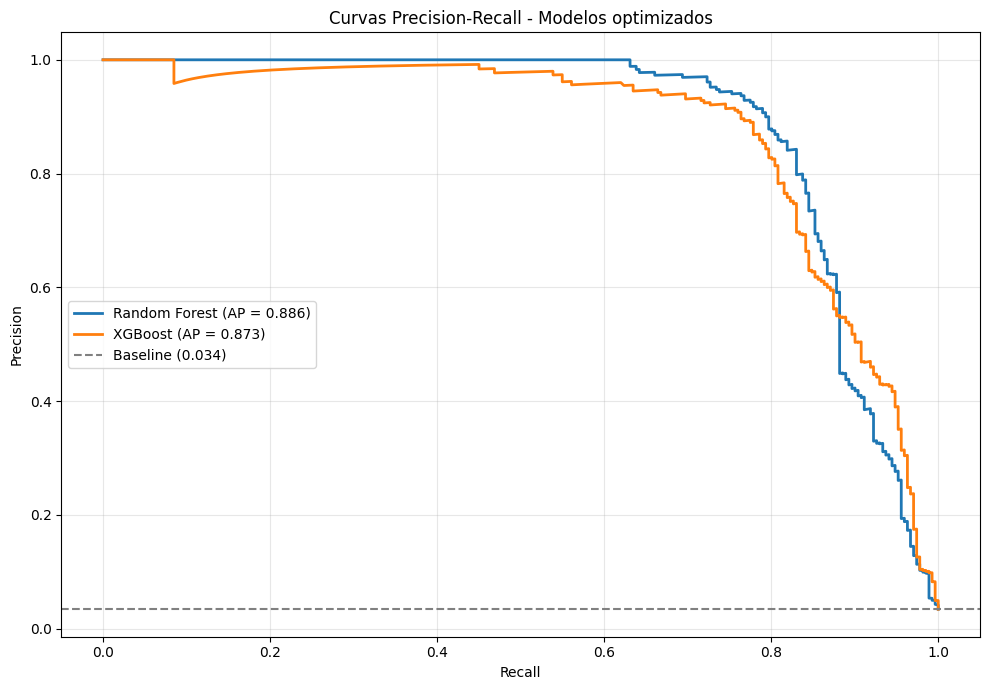

In [42]:
# 5.1 - Curvas Precision-Recall de los modelos candidatos


# Modelos con los mejores hiperparámetros encontrados
modelos_candidatos = {
    "Random Forest": clone(busqueda_rf.best_estimator_),
    "XGBoost": clone(busqueda_xgb.best_estimator_)
}

# Guardaremos las probabilidades fuera de muestra
probabilidades_oof = {}

plt.figure(figsize=(10, 7))

for nombre, modelo in modelos_candidatos.items():

    # Probabilidades fuera de muestra mediante CV
    probabilidades = cross_val_predict(
        modelo,
        X_train,
        y_train,
        cv=cv_externa,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    probabilidades_oof[nombre] = probabilidades

    # Calcular Precision-Recall
    precision, recall, thresholds = precision_recall_curve(
        y_train,
        probabilidades
    )

    ap = average_precision_score(
        y_train,
        probabilidades
    )

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{nombre} (AP = {ap:.3f})"
    )

# Línea de referencia: prevalencia de fallas
prevalencia = y_train.mean()

plt.axhline(
    prevalencia,
    color="gray",
    linestyle="--",
    label=f"Baseline ({prevalencia:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Curvas Precision-Recall - Modelos optimizados")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 5.1.1. Conclusiones del análisis Precision-Recall

Se construyeron curvas Precision-Recall para los modelos optimizados de Random Forest y XGBoost, utilizando predicciones fuera de muestra obtenidas mediante validación cruzada sobre el conjunto de desarrollo.

Random Forest alcanzó un **Average Precision de 0,886**, mientras que XGBoost obtuvo **0,873**. Ambos valores superan ampliamente la referencia correspondiente a la prevalencia de fallas del dataset, aproximadamente 0,034.

Las curvas muestran que ambos algoritmos mantienen niveles elevados de precisión cuando la proporción de fallas detectadas es moderada.

Sin embargo, al intentar aumentar el recall hacia valores próximos a 1, la precisión disminuye considerablemente. Esto implica que detectar una mayor proporción de fallas requiere aceptar una cantidad creciente de falsas alarmas.

Random Forest presenta un comportamiento generalmente superior en buena parte del recorrido de la curva, aunque existen regiones de recall elevado donde ambos modelos muestran resultados similares o se invierte parcialmente su relación.

**Implicancias para el proyecto:** el análisis evidencia que la selección del umbral de clasificación resulta fundamental para equilibrar la detección de fallas y la precisión de las alertas.

En la siguiente etapa se evaluarán diferentes umbrales utilizando exclusivamente información del conjunto de desarrollo, considerando el compromiso entre Precision, Recall y F1-score.

Las curvas obtenidas corresponden a modelos cuyos hiperparámetros fueron seleccionados previamente mediante el conjunto de desarrollo. Por lo tanto, se interpretan como herramientas exploratorias para la elección del umbral y no como una evaluación final independiente del procedimiento de selección.

## 5.2. Análisis y selección del umbral de clasificación

Los modelos de clasificación binaria generan probabilidades estimadas que posteriormente se convierten en predicciones mediante un umbral de decisión.

Aunque habitualmente se utiliza un umbral de 0,5, este valor no necesariamente representa la mejor opción para un problema de mantenimiento industrial.

Un umbral reducido puede aumentar la detección de fallas, pero también generar más falsas alarmas. Por el contrario, un umbral elevado puede mejorar la precisión de las alertas, pero dejar sin detectar una mayor proporción de fallas reales.

En esta sección analizaremos cómo varían Precision, Recall y F1-score según el umbral utilizado.

Se utilizarán las probabilidades fuera de muestra obtenidas previamente mediante validación cruzada sobre el conjunto de desarrollo.

Inicialmente se realizará un análisis exploratorio de distintos umbrales. Posteriormente se establecerá un criterio de selección y se verificará su desempeño mediante un procedimiento que evite evaluar la regla de decisión sobre los mismos datos empleados para seleccionarla.

El objetivo será identificar configuraciones que proporcionen un equilibrio razonable entre la detección de fallas y la cantidad de falsas alarmas, considerando las necesidades de una posible aplicación industrial.

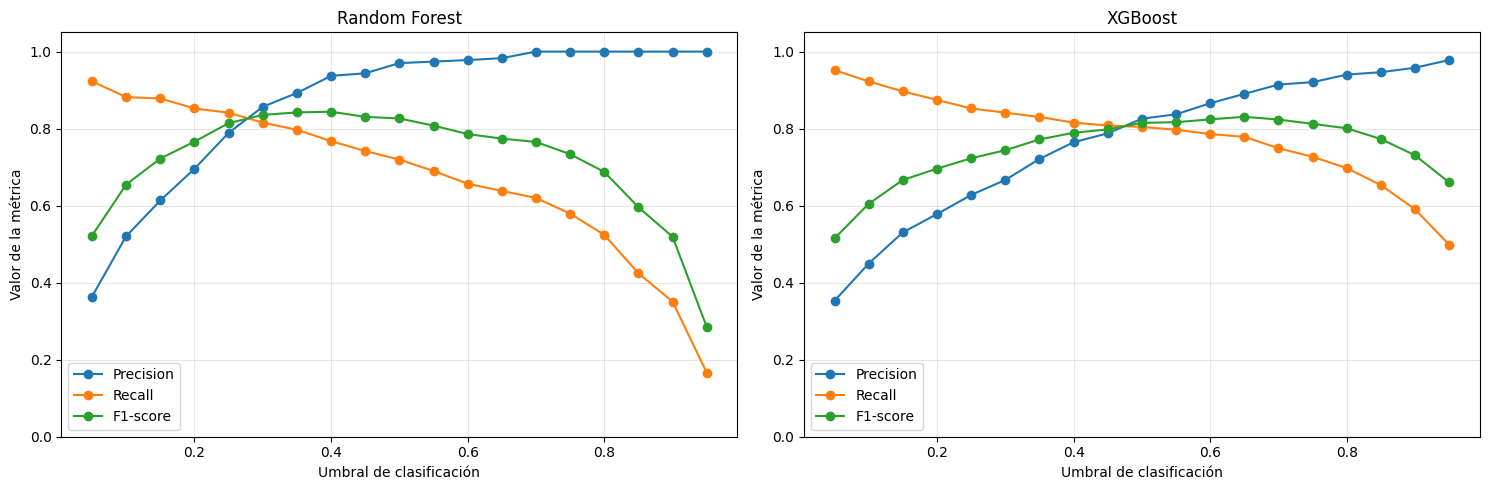

,Modelo,Umbral,Precision,Recall,F1,Falsas alarmas,Fallas omitidas
0,Random Forest,0.05,0.363901,0.922509,0.521921,437,21
1,Random Forest,0.10,0.520697,0.881919,0.654795,220,32
2,Random Forest,0.15,0.613402,0.878229,0.722307,150,33
3,Random Forest,0.20,0.695783,0.852399,0.766169,101,40
4,Random Forest,0.25,0.788927,0.841328,0.814286,61,43
5,Random Forest,0.30,0.856589,0.815498,0.835539,37,50
6,Random Forest,0.35,0.892562,0.797048,0.842105,26,55
7,Random Forest,0.40,0.936937,0.767528,0.843813,14,63
8,Random Forest,0.45,0.943662,0.741697,0.830579,12,70
9,Random Forest,0.50,0.970149,0.719557,0.826271,6,76


In [43]:
umbrales = np.arange(0.05, 0.96, 0.05)

resultados_umbrales = []

for nombre, probabilidades in probabilidades_oof.items():

    for umbral in umbrales:

        predicciones = (
            probabilidades >= umbral
        ).astype(int)

        resultados_umbrales.append({
            "Modelo": nombre,
            "Umbral": round(umbral, 2),
            "Precision": precision_score(
                y_train, predicciones,
                zero_division=0
            ),
            "Recall": recall_score(
                y_train, predicciones,
                zero_division=0
            ),
            "F1": f1_score(
                y_train, predicciones,
                zero_division=0
            ),
            "Falsas alarmas": int(
                ((predicciones == 1) & (y_train == 0)).sum()
            ),
            "Fallas omitidas": int(
                ((predicciones == 0) & (y_train == 1)).sum()
            )
        })

tabla_umbrales = pd.DataFrame(resultados_umbrales)

# Graficar métricas según umbral
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, nombre in zip(
    axes,
    probabilidades_oof.keys()
):

    datos = tabla_umbrales[
        tabla_umbrales["Modelo"] == nombre
    ]

    ax.plot(
        datos["Umbral"],
        datos["Precision"],
        marker="o",
        label="Precision"
    )

    ax.plot(
        datos["Umbral"],
        datos["Recall"],
        marker="o",
        label="Recall"
    )

    ax.plot(
        datos["Umbral"],
        datos["F1"],
        marker="o",
        label="F1-score"
    )

    ax.set_title(nombre)
    ax.set_xlabel("Umbral de clasificación")
    ax.set_ylabel("Valor de la métrica")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

display(tabla_umbrales)

### 5.2.1. Interpretación de las curvas según el umbral de clasificación

El análisis de diferentes umbrales de clasificación permitió observar cómo varían Precision, Recall y F1-score en los modelos Random Forest y XGBoost.

En ambos algoritmos se identifica un compromiso entre la precisión de las alertas y la proporción de fallas detectadas.

En Random Forest, el F1-score presenta sus valores más elevados aproximadamente entre los umbrales 0,35 y 0,40. A medida que se incrementa el umbral, la precisión aumenta, pero disminuye el recall.

Por su parte, XGBoost presenta una región de F1-score elevado aproximadamente entre 0,60 y 0,65, con una disminución más gradual del recall al modificar el umbral.

Estos resultados muestran que el umbral predeterminado de 0,5 no necesariamente representa el mejor compromiso entre ambas métricas.

**Implicancias para el proyecto:** la selección del umbral debe responder a un criterio explícito de evaluación, considerando tanto la capacidad de detectar fallas como la cantidad de falsas alarmas.

Los intervalos observados son exploratorios y no deben interpretarse como valores definitivos, debido a que fueron identificados utilizando las mismas predicciones empleadas para construir las curvas.

En consecuencia, será necesario establecer y validar una regla de selección antes de evaluar el modelo final sobre el conjunto de prueba.

## 5.3. Selección y validación del umbral de clasificación

Los análisis anteriores demostraron que modificar el umbral de clasificación produce cambios importantes en la precisión de las alertas y en la proporción de fallas detectadas.

Sin embargo, seleccionar el umbral que maximiza F1-score sobre un conjunto de observaciones y evaluar el modelo utilizando esas mismas observaciones puede generar resultados excesivamente optimistas.

Para evitar este problema, aplicaremos un procedimiento de **validación cruzada anidada**, separando la selección del umbral de su evaluación.

En cada partición externa:

1. Se optimizarán los hiperparámetros utilizando únicamente los datos de entrenamiento de esa partición.
2. Se generarán predicciones fuera de muestra mediante validación interna.
3. Se seleccionará el umbral que maximice F1-score sobre las predicciones internas.
4. Se entrenará el modelo con los datos de entrenamiento externos.
5. Se evaluará el modelo y el umbral seleccionado sobre la partición externa de validación.

Inicialmente utilizaremos F1-score como criterio de selección porque combina Precision y Recall.

Además, registraremos los falsos positivos y falsos negativos, dado que estos errores tienen implicancias diferentes para una posible aplicación industrial.

Comenzaremos con Random Forest y posteriormente repetiremos el procedimiento con XGBoost.

El conjunto de prueba final permanecerá completamente reservado hasta concluir la selección de modelos y umbrales.

In [44]:
# 5.3.1 - Selección y validación anidada del umbral: Random Forest



umbrales_candidatos = np.arange(0.05, 0.96, 0.05)

resultados_umbral_rf = []

# Validación externa
for fold, (idx_train, idx_val) in enumerate(
    cv_externa.split(X_train, y_train), start=1
):

    X_ent = X_train.iloc[idx_train]
    X_val = X_train.iloc[idx_val]

    y_ent = y_train.iloc[idx_train]
    y_val = y_train.iloc[idx_val]

    # 1. Optimización dentro del entrenamiento externo
    busqueda_interna = RandomizedSearchCV(
        estimator=clone(pipeline_rf_opt),
        param_distributions=parametros_rf,
        n_iter=20,
        scoring="average_precision",
        cv=cv_interna,
        random_state=42,
        n_jobs=-1,
        refit=True
    )

    busqueda_interna.fit(X_ent, y_ent)

    mejor_modelo = busqueda_interna.best_estimator_

    # 2. Probabilidades de validación interna
    probs_internas = cross_val_predict(
        clone(mejor_modelo),
        X_ent,
        y_ent,
        cv=cv_interna,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    # 3. Elegir umbral maximizando F1 interno
    f1_por_umbral = [
        f1_score(
            y_ent,
            (probs_internas >= u).astype(int),
            zero_division=0
        )
        for u in umbrales_candidatos
    ]

    mejor_umbral = float(
        umbrales_candidatos[np.argmax(f1_por_umbral)]
    )

    # 4. Evaluación sobre partición externa
    probs_val = mejor_modelo.predict_proba(X_val)[:, 1]

    pred_val = (probs_val >= mejor_umbral).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, pred_val, labels=[0, 1]
    ).ravel()

    resultados_umbral_rf.append({
        "Fold": fold,
        "Umbral": mejor_umbral,
        "Average Precision": average_precision_score(
            y_val, probs_val
        ),
        "Precision": precision_score(
            y_val, pred_val, zero_division=0
        ),
        "Recall": recall_score(
            y_val, pred_val, zero_division=0
        ),
        "F1": f1_score(
            y_val, pred_val, zero_division=0
        ),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "TN": int(tn)
    })

tabla_umbral_rf = pd.DataFrame(resultados_umbral_rf)

display(tabla_umbral_rf.round(4))

print("\nPromedio de métricas externas:")
display(
    tabla_umbral_rf[
        ["Umbral", "Average Precision", "Precision", "Recall", "F1"]
    ].mean().round(4)
)

print("\nDesviación estándar entre particiones:")
display(
    tabla_umbral_rf[
        ["Umbral", "Average Precision", "Precision", "Recall", "F1"]
    ].std().round(4)
)

,Fold,Umbral,Average Precision,Precision,Recall,F1,FP,FN,TP,TN
0,1,0.40,0.9216,0.9231,0.8889,0.9057,4,6,48,1542
1,2,0.35,0.8933,0.8800,0.8148,0.8462,6,10,44,1540
2,3,0.55,0.8767,1.0000,0.6481,0.7865,0,19,35,1546
3,4,0.45,0.9116,0.9773,0.7963,0.8776,1,11,43,1545
4,5,0.50,0.8418,1.0000,0.6727,0.8043,0,18,37,1545



Promedio de métricas externas:


Umbral               0.4500
Average Precision    0.8890
Precision            0.9561
Recall               0.7642
F1                   0.8440
dtype: float64


Desviación estándar entre particiones:


Umbral               0.0791
Average Precision    0.0315
Precision            0.0529
Recall               0.1012
F1                   0.0495
dtype: float64

### 5.3.1. Conclusiones de la selección y validación del umbral en Random Forest

Se aplicó un procedimiento de validación cruzada anidada para evaluar la selección de umbrales en Random Forest. En cada partición externa se optimizaron los hiperparámetros y se seleccionó un umbral utilizando predicciones de validación interna y F1-score como criterio.

Los umbrales seleccionados oscilaron entre **0,35 y 0,55**, con una media de **0,45** y una desviación estándar de **0,0791**, evidenciando cierta variabilidad entre las particiones.

El modelo obtuvo una precisión promedio del **95,61 %**, un recall del **76,42 %**, un F1-score de **0,8440** y un Average Precision de **0,8890**.

Al acumular los resultados de las cinco particiones externas, se identificaron correctamente 207 de las 271 fallas, mientras que 64 no fueron detectadas. Se registraron 11 falsas alarmas sobre 8.000 observaciones evaluadas fuera de muestra.

Estos resultados muestran un equilibrio prometedor entre detección de fallas y precisión de las alertas. No obstante, la cantidad de fallas omitidas continúa siendo relevante desde una perspectiva industrial.

La variabilidad de los umbrales también indica que no resulta adecuado adoptar automáticamente su media como umbral definitivo.

**Implicancias para el proyecto:** Random Forest continúa siendo un candidato sólido para la clasificación de fallas. Antes de seleccionar el modelo y su umbral final, aplicaremos el mismo procedimiento a XGBoost y compararemos ambos resultados.

La evaluación definitiva se realizará posteriormente sobre el conjunto de prueba reservado, sin utilizarlo para seleccionar modelos ni umbrales.

### 5.3.2. Selección y validación del umbral en XGBoost

Para comparar los dos modelos candidatos bajo condiciones equivalentes, aplicaremos a XGBoost el mismo procedimiento de selección y validación del umbral utilizado con Random Forest.

En cada partición externa, se realizará una optimización de hiperparámetros mediante validación interna. Posteriormente, se seleccionará el umbral que maximice el F1-score utilizando predicciones fuera de muestra del conjunto de entrenamiento correspondiente.

El modelo y el umbral seleccionados se evaluarán sobre la partición externa, que no habrá participado en ninguna de estas decisiones.

Registraremos Precision, Recall, F1-score, Average Precision y los componentes de la matriz de confusión.

El objetivo es determinar si XGBoost consigue una mejora en la detección de fallas y qué impacto tiene sobre las falsas alarmas, manteniendo reservado el conjunto de prueba final.

In [45]:
# 5.3.2 - Selección y validación del umbral: XGBoost

resultados_umbral_xgb = []

for fold, (idx_train, idx_val) in enumerate(
    cv_externa.split(X_train, y_train), start=1
):

    X_ent = X_train.iloc[idx_train]
    X_val = X_train.iloc[idx_val]

    y_ent = y_train.iloc[idx_train]
    y_val = y_train.iloc[idx_val]

    # 1. Optimización interna
    busqueda_interna_xgb = RandomizedSearchCV(
        estimator=clone(pipeline_xgb_opt),
        param_distributions=parametros_xgb,
        n_iter=20,
        scoring="average_precision",
        cv=cv_interna,
        random_state=42,
        n_jobs=1,
        refit=True
    )

    busqueda_interna_xgb.fit(X_ent, y_ent)

    mejor_modelo_xgb = busqueda_interna_xgb.best_estimator_

    # 2. Probabilidades fuera de muestra internas
    probs_internas = cross_val_predict(
        clone(mejor_modelo_xgb),
        X_ent,
        y_ent,
        cv=cv_interna,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    # 3. Selección interna del umbral
    f1_por_umbral = [
        f1_score(
            y_ent,
            (probs_internas >= u).astype(int),
            zero_division=0
        )
        for u in umbrales_candidatos
    ]

    mejor_umbral = float(
        umbrales_candidatos[np.argmax(f1_por_umbral)]
    )

    # 4. Evaluación externa
    probs_val = mejor_modelo_xgb.predict_proba(X_val)[:, 1]
    pred_val = (probs_val >= mejor_umbral).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, pred_val, labels=[0, 1]
    ).ravel()

    resultados_umbral_xgb.append({
        "Fold": fold,
        "Umbral": mejor_umbral,
        "Average Precision": average_precision_score(y_val, probs_val),
        "Precision": precision_score(y_val, pred_val, zero_division=0),
        "Recall": recall_score(y_val, pred_val, zero_division=0),
        "F1": f1_score(y_val, pred_val, zero_division=0),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "TN": int(tn)
    })

tabla_umbral_xgb = pd.DataFrame(resultados_umbral_xgb)

display(tabla_umbral_xgb.round(4))

print("\nPromedio de métricas externas:")
display(
    tabla_umbral_xgb[
        ["Umbral", "Average Precision", "Precision", "Recall", "F1"]
    ].mean().round(4)
)

print("\nDesviación estándar entre particiones:")
display(
    tabla_umbral_xgb[
        ["Umbral", "Average Precision", "Precision", "Recall", "F1"]
    ].std().round(4)
)

print("\nTotales de errores y aciertos:")
display(
    tabla_umbral_xgb[["FP", "FN", "TP", "TN"]].sum()
)

,Fold,Umbral,Average Precision,Precision,Recall,F1,FP,FN,TP,TN
0,1,0.30,0.8607,0.8103,0.8704,0.8393,11,7,47,1535
1,2,0.50,0.8934,0.8776,0.7963,0.8350,6,11,43,1540
2,3,0.30,0.8983,0.8542,0.7593,0.8039,7,13,41,1539
3,4,0.80,0.8821,0.8679,0.8519,0.8598,7,8,46,1539
4,5,0.45,0.8235,0.8864,0.7091,0.7879,5,16,39,1540



Promedio de métricas externas:


Umbral               0.4700
Average Precision    0.8716
Precision            0.8593
Recall               0.7974
F1                   0.8252
dtype: float64


Desviación estándar entre particiones:


Umbral               0.2049
Average Precision    0.0306
Precision            0.0298
Recall               0.0662
F1                   0.0289
dtype: float64


Totales de errores y aciertos:


FP      36
FN      55
TP     216
TN    7693
dtype: int64

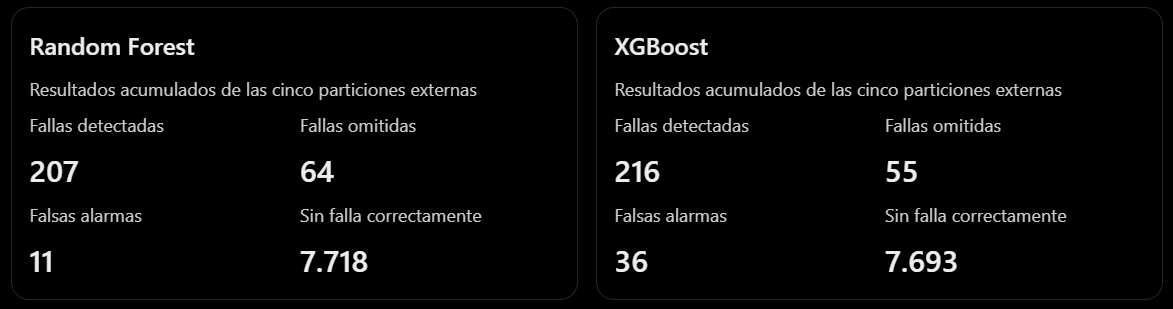

#### Conclusiones de la selección y validación del umbral en XGBoost

Se aplicó un procedimiento de validación cruzada anidada para seleccionar y evaluar el umbral de clasificación de XGBoost, utilizando F1-score como criterio de selección interna.

Los resultados mostraron un **Average Precision promedio de 0,8716**, una precisión del **85,93 %**, un recall del **79,74 %** y un F1-score de **0,8252**.

Los umbrales seleccionados oscilaron entre 0,30 y 0,80, con una media de 0,47 y una desviación estándar de 0,2049. Esta variabilidad indica que la selección del umbral es relativamente sensible a las particiones utilizadas.

Al acumular los resultados de las cinco particiones externas, XGBoost identificó correctamente 216 de las 271 fallas, omitió 55 y generó 36 falsas alarmas.

En comparación, Random Forest detectó 207 fallas, omitió 64 y produjo solamente 11 falsas alarmas.

Por lo tanto, XGBoost consiguió detectar nueve fallas adicionales, pero a cambio de generar 25 falsas alarmas adicionales.

**Implicancias para el proyecto:** Random Forest presenta un mejor equilibrio según F1-score y Average Precision, además de una mayor estabilidad en los umbrales seleccionados.

Sin embargo, no es posible determinar qué modelo resulta operativamente más conveniente sin considerar las consecuencias de ambos tipos de errores.

En consecuencia, se realizará un análisis económico mediante escenarios de costos simulados para evaluar cómo cambia la elección del modelo según el costo de una falsa alarma y el de una falla no detectada.

Estos resultados corresponden al conjunto de desarrollo mediante validación cruzada anidada. El conjunto de prueba final permanece reservado.

## 5.4. Evaluación económica mediante escenarios de costos simulados

En un contexto de mantenimiento industrial, la utilidad de un modelo de clasificación no depende únicamente de sus métricas estadísticas, sino también de las consecuencias operativas de sus predicciones.

Una falsa alarma puede generar inspecciones innecesarias y utilización adicional de recursos. Por otro lado, una falla no detectada podría provocar interrupciones operativas, costos de reparación o pérdidas de producción.

Para estudiar este compromiso, realizaremos un análisis económico utilizando los resultados obtenidos mediante validación cruzada anidada.

Se considerarán dos tipos de errores:

- **Falsos positivos (FP):** alertas de falla emitidas cuando el registro no presenta una falla real.
- **Falsos negativos (FN):** fallas registradas que el modelo no consigue detectar.

El costo total se calculará mediante la expresión:

\[
C_{\text{total}} = FP \cdot C_{FP} + FN \cdot C_{FN}
\]

Dado que AI4I 2020 no proporciona información económica real, se utilizarán escenarios hipotéticos expresados en unidades de costo relativas.

El objetivo será determinar cómo cambia la conveniencia de Random Forest y XGBoost cuando se modifica la relación entre el costo de una falsa alarma y el de una falla no detectada.

Este análisis constituye una simulación de decisiones operativas y no debe interpretarse como una estimación de costos reales de mantenimiento industrial.

,Modelo,Costo FP,Costo FN,Falsas alarmas,Fallas omitidas,Costo total
0,Random Forest,1,1,11,64,75
1,XGBoost,1,1,36,55,91
2,Random Forest,1,2,11,64,139
3,XGBoost,1,2,36,55,146
4,Random Forest,1,3,11,64,203
5,XGBoost,1,3,36,55,201
6,Random Forest,1,5,11,64,331
7,XGBoost,1,5,36,55,311
8,Random Forest,1,10,11,64,651
9,XGBoost,1,10,36,55,586


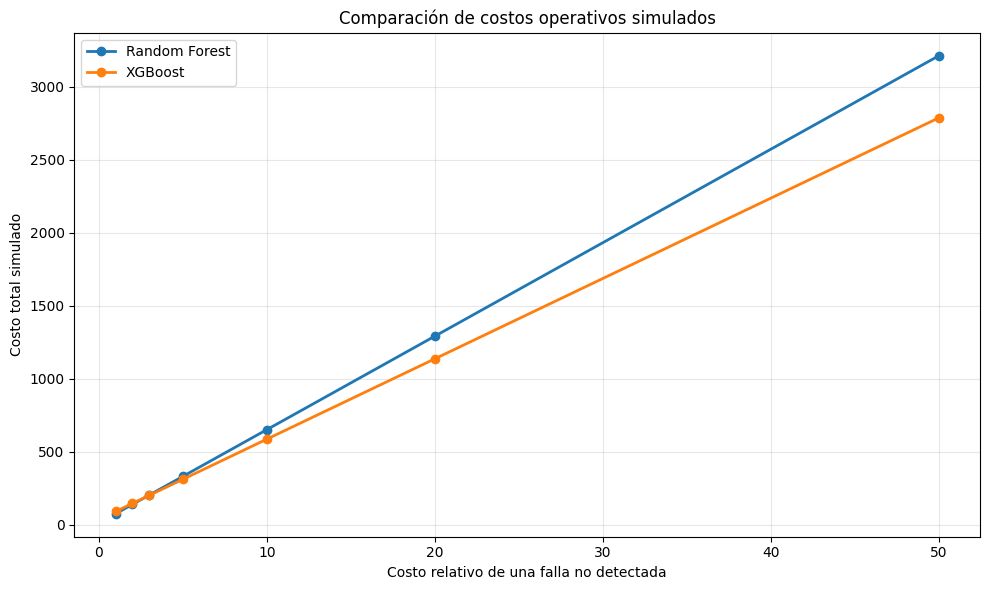

In [46]:
# 5.4 - Evaluación económica de modelos
# Recuperar errores de las validaciones externas
errores_modelos = {
    "Random Forest": {
        "FP": int(tabla_umbral_rf["FP"].sum()),
        "FN": int(tabla_umbral_rf["FN"].sum())
    },
    "XGBoost": {
        "FP": int(tabla_umbral_xgb["FP"].sum()),
        "FN": int(tabla_umbral_xgb["FN"].sum())
    }
}

# Costo relativo de una falsa alarma
costo_fp = 1

# Diferentes escenarios para una falla omitida
costos_fn = [1, 2, 3, 5, 10, 20, 50]

resultados_costos = []

for costo_fn in costos_fn:
    for modelo, errores in errores_modelos.items():

        costo_total = (
            errores["FP"] * costo_fp
            + errores["FN"] * costo_fn
        )

        resultados_costos.append({
            "Modelo": modelo,
            "Costo FP": costo_fp,
            "Costo FN": costo_fn,
            "Falsas alarmas": errores["FP"],
            "Fallas omitidas": errores["FN"],
            "Costo total": costo_total
        })

tabla_costos = pd.DataFrame(resultados_costos)

display(tabla_costos)

# Gráfico comparativo
plt.figure(figsize=(10, 6))

for modelo in tabla_costos["Modelo"].unique():

    datos = tabla_costos[
        tabla_costos["Modelo"] == modelo
    ]

    plt.plot(
        datos["Costo FN"],
        datos["Costo total"],
        marker="o",
        linewidth=2,
        label=modelo
    )

plt.xlabel("Costo relativo de una falla no detectada")
plt.ylabel("Costo total simulado")
plt.title("Comparación de costos operativos simulados")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5.5. Estudio de ablación de características (Feature Ablation)

Durante el análisis exploratorio construimos características derivadas basadas en relaciones físicas entre las variables operativas del dataset AI4I 2020.

En particular, incorporamos la diferencia de temperaturas (`Temperature_difference_K`) y la potencia mecánica rotacional aproximada (`Mechanical_power_W`).

Aunque estas características presentan una interpretación física, su incorporación no garantiza automáticamente una mejora en el desempeño de los algoritmos.

Para evaluar su utilidad, realizaremos un **estudio de ablación de características**, comparando dos configuraciones de Random Forest:

- **Modelo original:** utiliza las seis características originales del dataset.
- **Modelo ampliado:** utiliza las seis características originales más las dos variables derivadas.

Se mantendrán constantes el algoritmo, los hiperparámetros, las particiones de validación y el criterio de evaluación.

De esta manera, la principal diferencia entre ambos experimentos será el conjunto de características utilizadas.

La evaluación se realizará mediante validación cruzada estratificada de cinco particiones sobre el conjunto de desarrollo, utilizando Average Precision como métrica principal y Precision, Recall y F1-score como métricas complementarias.

El objetivo será determinar si las características derivadas mejoran la capacidad de clasificación, aportan información redundante o producen un efecto negativo sobre el rendimiento.

Los resultados se interpretarán como evidencia experimental sobre el aporte de la ingeniería de características, sin asumir relaciones causales ni utilizar el conjunto de prueba final.

In [47]:
# 5.5 - Estudio de ablación de características
# Hiperparámetros seleccionados previamente
mejores_parametros_rf = {
    "n_estimators": 200,
    "max_depth": 15,
    "min_samples_split": 5,
    "min_samples_leaf": 1,
    "max_features": "log2",
    "class_weight": None,
    "random_state": 42,
    "n_jobs": 1
}

# Random Forest con características originales
pipeline_rf_original = Pipeline([
    ("preprocesamiento", clone(preprocesamiento_original)),
    ("modelo", RandomForestClassifier(
        **mejores_parametros_rf
    ))
])

# Random Forest con características ampliadas
pipeline_rf_ampliado = Pipeline([
    ("preprocesamiento", clone(preprocesamiento)),
    ("modelo", RandomForestClassifier(
        **mejores_parametros_rf
    ))
])

# Evaluación de ambos conjuntos
resultados_ablacion = {}

configuraciones = {
    "Original": (pipeline_rf_original, X_original_train),
    "Ampliado": (pipeline_rf_ampliado, X_train)
}

for nombre, (pipeline, datos) in configuraciones.items():

    resultados = cross_validate(
        pipeline,
        datos,
        y_train,
        cv=cv,
        scoring=metricas_logistica,
        n_jobs=-1
    )

    resultados_ablacion[nombre] = resultados

# Construcción de tabla comparativa
filas = []

for nombre, resultados in resultados_ablacion.items():

    fila = {"Conjunto": nombre}

    for metrica in metricas_logistica:
        fila[metrica] = resultados[
            f"test_{metrica}"
        ].mean()

    filas.append(fila)

tabla_ablacion = pd.DataFrame(filas)

display(tabla_ablacion.round(4))

# Diferencias: ampliado - original
diferencias = (
    tabla_ablacion
    .set_index("Conjunto")
    .loc["Ampliado"]
    -
    tabla_ablacion
    .set_index("Conjunto")
    .loc["Original"]
)

print("\nDiferencia de rendimiento (Ampliado - Original):")
display(diferencias.round(4))

,Conjunto,average_precision,precision,recall,f1,balanced_accuracy
0,Original,0.7938,0.8625,0.5868,0.6959,0.7917
1,Ampliado,0.8859,0.9714,0.7271,0.8297,0.8632



Diferencia de rendimiento (Ampliado - Original):


average_precision    0.0921
precision            0.1089
recall               0.1403
f1                   0.1337
balanced_accuracy    0.0715
dtype: float64

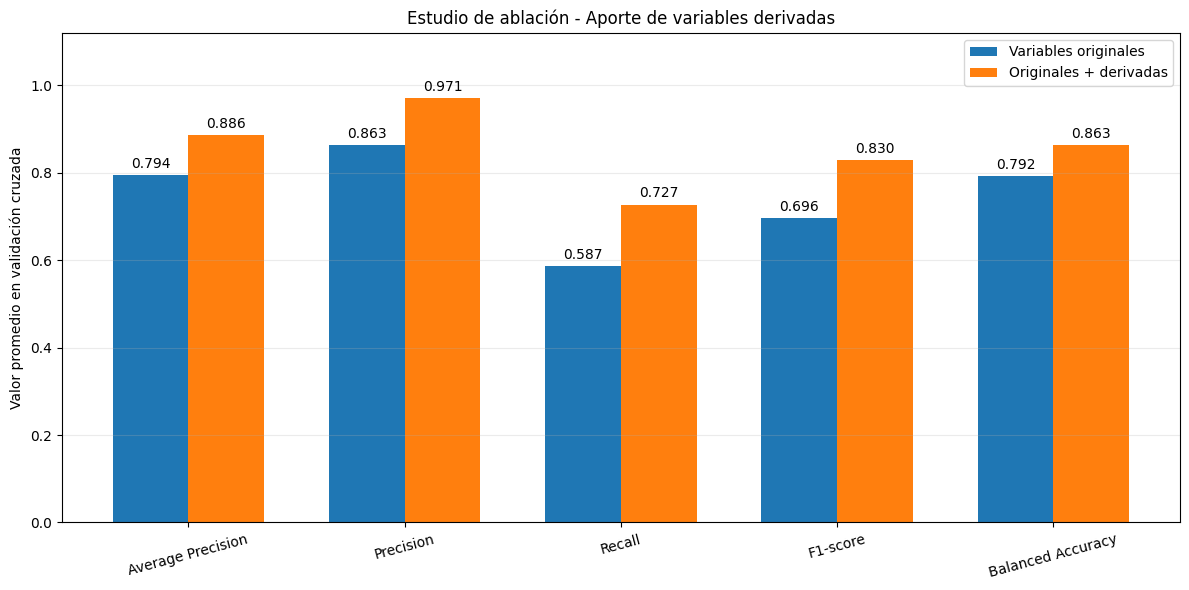

In [48]:
# 5.5 - Visualización del estudio de ablación


metricas_grafico = [
    "average_precision",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy"
]

nombres_metricas = [
    "Average Precision",
    "Precision",
    "Recall",
    "F1-score",
    "Balanced Accuracy"
]

original = (
    tabla_ablacion
    .set_index("Conjunto")
    .loc["Original", metricas_grafico]
    .astype(float)
    .values
)

ampliado = (
    tabla_ablacion
    .set_index("Conjunto")
    .loc["Ampliado", metricas_grafico]
    .astype(float)
    .values
)

x = np.arange(len(metricas_grafico))
ancho = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

barras_original = ax.bar(
    x - ancho / 2,
    original,
    ancho,
    label="Variables originales"
)

barras_ampliado = ax.bar(
    x + ancho / 2,
    ampliado,
    ancho,
    label="Originales + derivadas"
)

ax.bar_label(barras_original, fmt="%.3f", padding=3)
ax.bar_label(barras_ampliado, fmt="%.3f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(nombres_metricas, rotation=15)

ax.set_ylim(0, 1.12)
ax.set_ylabel("Valor promedio en validación cruzada")

ax.set_title(
    "Estudio de ablación - Aporte de variables derivadas"
)

ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### 5.5.1. Conclusiones del estudio de ablación

El estudio de ablación permitió evaluar el aporte de las características derivadas mediante la comparación de dos configuraciones de Random Forest: una con las seis variables originales y otra que incorpora la diferencia de temperaturas y la potencia mecánica rotacional aproximada.

Ambos modelos fueron evaluados utilizando las mismas particiones de validación cruzada y los mismos hiperparámetros.

Los resultados mostraron mejoras en todas las métricas consideradas al incorporar las variables derivadas.

El **Average Precision aumentó de 0,7938 a 0,8859**, lo que representa una mejora de 0,0921 puntos en la escala de la métrica.

La precisión pasó del **86,25 % al 97,14 %**, mientras que el recall aumentó del **58,68 % al 72,71 %**.

Asimismo, el F1-score mejoró de 0,6959 a 0,8297 y la Balanced Accuracy aumentó del 79,17 % al 86,32 %.

Estos resultados aportan evidencia de que la ingeniería de características basada en relaciones físicas contribuyó favorablemente al desempeño predictivo de Random Forest en las condiciones evaluadas.

En particular, la mejora simultánea de Precision y Recall resulta relevante para el objetivo del proyecto, ya que buscamos detectar fallas sin incrementar innecesariamente las falsas alarmas.

**Limitaciones del experimento:** la comparación evalúa el efecto conjunto de ambas variables derivadas, sin identificar su contribución individual. Además, los hiperparámetros utilizados fueron seleccionados previamente con el conjunto ampliado, por lo que los resultados deben interpretarse como evidencia exploratoria y no como una prueba independiente de superioridad estadística.

**Implicancias para el proyecto:** se conservarán las características derivadas como parte de la configuración candidata para el modelo final, sujeto a las restantes verificaciones metodológicas y a la evaluación final sobre datos de prueba no utilizados durante el desarrollo.

### 5.5.2. Estudio de ablación individual de características derivadas

En el experimento anterior se observó que la incorporación conjunta de `Temperature_difference_K` y `Mechanical_power_W` mejoró el desempeño de Random Forest en todas las métricas evaluadas.

Sin embargo, ese análisis no permite determinar cuál de las dos características aporta una mayor contribución.

Para profundizar esta investigación, compararemos cuatro configuraciones:

1. **Original:** únicamente las seis características originales.
2. **Original + diferencia térmica:** incorpora `Temperature_difference_K`.
3. **Original + potencia mecánica:** incorpora `Mechanical_power_W`.
4. **Ampliado:** incorpora ambas características derivadas.

Se utilizarán los mismos hiperparámetros de Random Forest, las mismas particiones de validación cruzada y las mismas métricas de evaluación.

Este procedimiento permitirá analizar la contribución individual de cada característica y estudiar si su incorporación conjunta produce una mejora adicional.

Se utilizará Average Precision como métrica principal, complementada con Precision, Recall y F1-score.

Los resultados se interpretarán como evidencia experimental condicionada a la configuración evaluada, considerando que los hiperparámetros fueron seleccionados previamente utilizando el conjunto ampliado.

No se utilizará el conjunto de prueba final durante esta comparación.

In [49]:
# 5.5.2 - Ablación individual de características derivadas
# Cuatro configuraciones de características
configuraciones_ablacion = {
    "Original": variables_numericas_originales,

    "Original + Delta T": (
        variables_numericas_originales
        + ["Temperature_difference_K"]
    ),

    "Original + Potencia": (
        variables_numericas_originales
        + ["Mechanical_power_W"]
    ),

    "Ampliado": (
        variables_numericas_originales
        + variables_derivadas
    )
}

resultados_ablacion_individual = []

for nombre, numericas in configuraciones_ablacion.items():

    columnas = variables_categoricas + numericas

    # Utilizamos únicamente registros de desarrollo
    X_configuracion = X_train[columnas].copy()

    # Preprocesamiento específico de esta configuración
    transformador = ColumnTransformer(
        transformers=[
            (
                "categoricas",
                OneHotEncoder(handle_unknown="ignore"),
                variables_categoricas
            ),
            (
                "numericas",
                StandardScaler(),
                numericas
            )
        ]
    )

    modelo = Pipeline([
        ("preprocesamiento", transformador),
        ("modelo", RandomForestClassifier(
            **mejores_parametros_rf
        ))
    ])

    # Mismas particiones para todas las configuraciones
    resultados = cross_validate(
        modelo,
        X_configuracion,
        y_train,
        cv=cv,
        scoring=metricas_logistica,
        n_jobs=-1
    )

    fila = {"Configuración": nombre}

    for metrica in metricas_logistica:
        fila[metrica] = resultados[
            f"test_{metrica}"
        ].mean()

    resultados_ablacion_individual.append(fila)

# Tabla comparativa
tabla_ablacion_individual = pd.DataFrame(
    resultados_ablacion_individual
)

display(tabla_ablacion_individual.round(4))

,Configuración,average_precision,precision,recall,f1,balanced_accuracy
0,Original,0.7938,0.8625,0.5868,0.6959,0.7917
1,Original + Delta T,0.8331,0.8995,0.6459,0.7494,0.8217
2,Original + Potencia,0.8570,0.9745,0.6385,0.7689,0.8189
3,Ampliado,0.8859,0.9714,0.7271,0.8297,0.8632


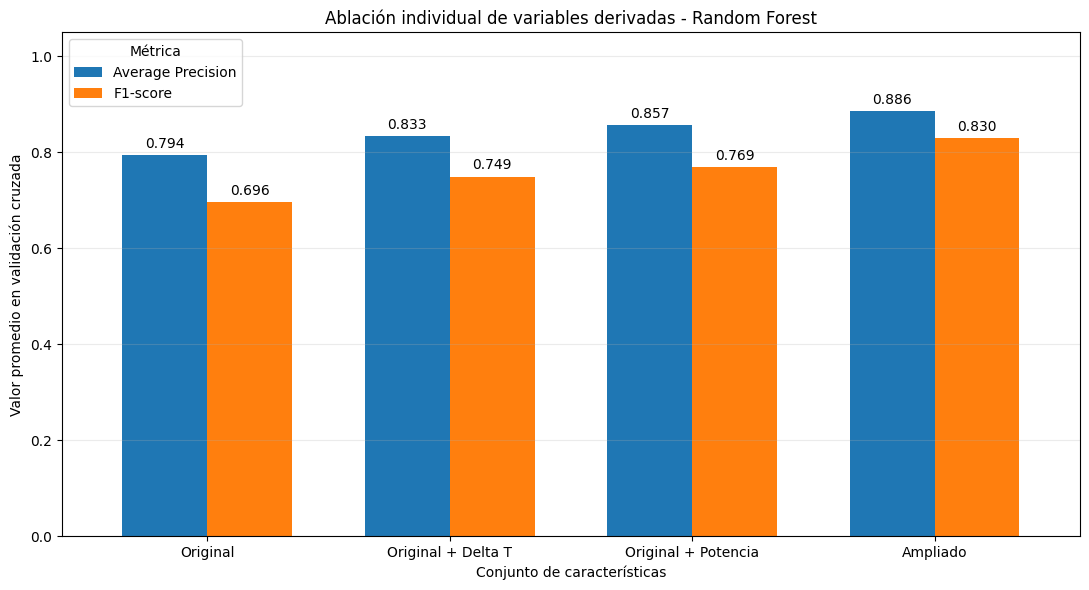

In [50]:
# Comparación visual de las cuatro configuraciones

metricas_grafico = ["average_precision", "f1"]

df_grafico = (
    tabla_ablacion_individual
    .set_index("Configuración")[metricas_grafico]
)

ax = df_grafico.plot(
    kind="bar",
    figsize=(11, 6),
    rot=0,
    width=0.7
)

ax.set_title(
    "Ablación individual de variables derivadas - Random Forest"
)
ax.set_ylabel("Valor promedio en validación cruzada")
ax.set_xlabel("Conjunto de características")
ax.set_ylim(0, 1.05)

ax.legend(
    ["Average Precision", "F1-score"],
    title="Métrica"
)

ax.grid(axis="y", alpha=0.25)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

plt.tight_layout()
plt.show()

#### Conclusiones del estudio de ablación individual

Se realizó un estudio de ablación individual para evaluar la contribución de las características derivadas `Temperature_difference_K` y `Mechanical_power_W` al desempeño de Random Forest.

Se compararon cuatro configuraciones, manteniendo constantes los hiperparámetros del algoritmo y las particiones de validación cruzada.

Los resultados mostraron que ambas características aportan mejoras cuando se incorporan individualmente:

- **Diferencia térmica:** incrementó Average Precision de 0,7938 a 0,8331 y F1-score de 0,6959 a 0,7494.
- **Potencia mecánica:** incrementó Average Precision a 0,8570 y F1-score a 0,7689, mostrando una contribución individual mayor en estas métricas.
- **Ambas características:** alcanzaron los mejores resultados globales, con Average Precision de 0,8859, recall de 72,71 % y F1-score de 0,8297.

Estos resultados muestran que representar explícitamente relaciones físicas entre las condiciones operativas facilita el aprendizaje del algoritmo en las configuraciones evaluadas.

Aunque ambas variables se calculan a partir de características originales, su incorporación permite que Random Forest represente de manera más efectiva determinados patrones asociados a fallas.

**Implicancias para el proyecto:** se conservarán ambas características derivadas como candidatas para el modelo final, dado que su incorporación conjunta obtuvo el mejor rendimiento de las cuatro configuraciones evaluadas.

No obstante, el experimento utiliza hiperparámetros seleccionados previamente con el conjunto ampliado. Por lo tanto, los resultados se interpretarán como evidencia exploratoria y deberán considerarse junto con las restantes evaluaciones antes de establecer conclusiones definitivas de generalización.

## 5.6. Selección del modelo y del umbral de clasificación

A partir de los experimentos realizados, se selecciona Random Forest como algoritmo principal para la evaluación final.

Esta elección se fundamenta en los resultados de validación cruzada anidada, donde presentó un Average Precision y un F1-score superiores a los obtenidos por XGBoost, además de una menor cantidad de falsas alarmas.

Asimismo, el estudio de ablación mostró que la incorporación de las características derivadas `Temperature_difference_K` y `Mechanical_power_W` mejoró el rendimiento del clasificador bajo las configuraciones evaluadas.

Por este motivo, se utilizará el conjunto ampliado de ocho variables predictoras.

### Criterio de selección del umbral

Para convertir las probabilidades estimadas en alertas binarias, seleccionaremos un umbral mediante la maximización del F1-score sobre predicciones fuera de muestra obtenidas exclusivamente del conjunto de desarrollo.

El F1-score permite considerar conjuntamente Precision y Recall, evitando maximizar únicamente la detección de fallas sin tener en cuenta las falsas alarmas.

El procedimiento utilizará las configuraciones de hiperparámetros seleccionadas previamente y no incorporará información del conjunto de prueba.

Los resultados de la selección del umbral se interpretarán como parte del proceso de desarrollo y no como una estimación independiente de rendimiento final.

Una vez definido el umbral, el modelo se ajustará utilizando todo el conjunto de desarrollo y se evaluará posteriormente una única vez sobre los datos de prueba reservados.

In [51]:
# 5.6 - Selección del umbral definitivo de Random Forest


# Probabilidades fuera de muestra del conjunto de desarrollo
probs_rf = probabilidades_oof["Random Forest"]

# Umbrales candidatos
umbrales_finales = np.arange(0.05, 0.951, 0.01)

resultados_seleccion = []

for umbral in umbrales_finales:

    predicciones = (probs_rf >= umbral).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        predicciones,
        labels=[0, 1]
    ).ravel()

    resultados_seleccion.append({
        "Umbral": round(float(umbral), 2),
        "Precision": precision_score(
            y_train, predicciones, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predicciones, zero_division=0
        ),
        "F1": f1_score(
            y_train, predicciones, zero_division=0
        ),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "TN": int(tn)
    })

tabla_seleccion_umbral = pd.DataFrame(resultados_seleccion)

# Seleccionar el umbral con mayor F1
# En caso de empate, elegir el umbral más alto
mejor_fila = tabla_seleccion_umbral.sort_values(
    ["F1", "Umbral"],
    ascending=[False, False]
).iloc[0]

umbral_final_rf = float(mejor_fila["Umbral"])

print("Umbral seleccionado:", umbral_final_rf)

print("\nMétricas exploratorias en desarrollo:")
display(
    mejor_fila.to_frame(name="Resultado").round(4)
)

# Conservar el modelo optimizado para el ajuste final

modelo_final_rf = clone(busqueda_rf.best_estimator_)

print("\nModelo final preparado para entrenamiento.")

Umbral seleccionado: 0.37

Métricas exploratorias en desarrollo:


,Resultado
Umbral,0.3700
Precision,0.9145
Recall,0.7897
F1,0.8475
FP,20.0000
FN,57.0000
TP,214.0000
TN,7709.0000



Modelo final preparado para entrenamiento.


### 5.6.1. Conclusiones de la selección del modelo y umbral

A partir de los experimentos realizados, se seleccionó Random Forest como modelo principal para la evaluación final, utilizando el conjunto ampliado de ocho características predictoras.

Esta decisión se fundamenta en su desempeño durante la validación cruzada anidada, su elevada precisión y la menor cantidad de falsas alarmas respecto de XGBoost.

Para establecer una regla de clasificación reproducible, se analizaron diferentes umbrales mediante predicciones fuera de muestra sobre el conjunto de desarrollo, seleccionando aquel que maximizó el F1-score.

El umbral seleccionado fue **0,37**, con una precisión exploratoria del **91,45 %**, un recall del **78,97 %** y un F1-score de **0,8475**.

Con esta configuración se identificaron correctamente 214 de las 271 fallas del conjunto de desarrollo, mientras que se registraron 20 falsas alarmas y 57 fallas omitidas.

Estos resultados sugieren un compromiso favorable entre detección de fallas y precisión de las alertas.

No obstante, dado que el umbral fue seleccionado utilizando estas mismas predicciones, sus métricas no constituyen una evaluación completamente independiente del proceso de selección.

**Configuración seleccionada:** Random Forest optimizado, ocho características predictoras y umbral de decisión 0,37.

Esta configuración se mantendrá fija durante la evaluación sobre el conjunto de prueba, que no participó en la selección del algoritmo, los hiperparámetros ni el umbral.

Los resultados del test permitirán estimar el desempeño final del prototipo sobre observaciones no utilizadas durante el desarrollo.

## 5.7. Evaluación final sobre el conjunto de prueba

Una vez seleccionado el algoritmo, sus hiperparámetros y el umbral de clasificación, realizaremos la evaluación final del modelo.

Se utilizará Random Forest con las ocho características predictoras y el umbral de decisión previamente establecido en 0,37.

El modelo será entrenado utilizando los 8.000 registros del conjunto de desarrollo y posteriormente evaluado sobre los 2.000 registros del conjunto de prueba, que permanecieron reservados durante las etapas anteriores.

Se calcularán Average Precision, Precision, Recall, F1-score y Balanced Accuracy, junto con la matriz de confusión.

También se analizará la cantidad de falsas alarmas y fallas omitidas, dado que estos errores tienen implicancias diferentes en mantenimiento industrial.

Los resultados permitirán evaluar el desempeño del modelo seleccionado sobre observaciones que no participaron en su entrenamiento ni en la selección de su configuración.

Esta evaluación representa una estimación del rendimiento sobre el dataset sintético y no garantiza resultados equivalentes en maquinaria industrial real.

,Métrica,Resultado
0,Average Precision,0.8881
1,Precision,0.9032
2,Recall,0.8235
3,F1-score,0.8615
4,Balanced Accuracy,0.9102


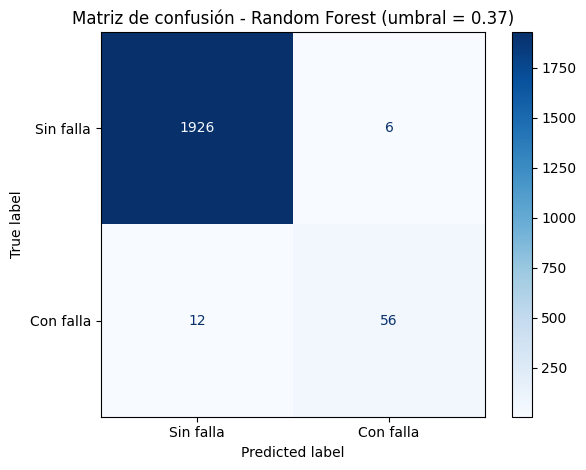


Resumen de clasificación:
Fallas detectadas: 56
Fallas omitidas: 12
Falsas alarmas: 6
Registros sin falla correctamente clasificados: 1926


In [52]:
# 5.7 - Evaluación final de Random Forest sobre test



# Entrenar modelo definitivo con todo el conjunto de desarrollo
modelo_final_rf.fit(X_train, y_train)

# Probabilidades sobre test
probabilidades_test = modelo_final_rf.predict_proba(X_test)[:, 1]

# Aplicar el umbral seleccionado previamente
predicciones_test = (
    probabilidades_test >= umbral_final_rf
).astype(int)

# Calcular métricas finales
metricas_finales = {
    "Average Precision": average_precision_score(
        y_test, probabilidades_test
    ),
    "Precision": precision_score(
        y_test, predicciones_test, zero_division=0
    ),
    "Recall": recall_score(
        y_test, predicciones_test, zero_division=0
    ),
    "F1-score": f1_score(
        y_test, predicciones_test, zero_division=0
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_test, predicciones_test
    )
}

tabla_metricas_finales = pd.DataFrame(
    list(metricas_finales.items()),
    columns=["Métrica", "Resultado"]
)

display(tabla_metricas_finales.round(4))

# Matriz de confusión
matriz_final = confusion_matrix(
    y_test,
    predicciones_test,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_final,
    display_labels=["Sin falla", "Con falla"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title(
    f"Matriz de confusión - Random Forest (umbral = {umbral_final_rf:.2f})"
)

plt.tight_layout()
plt.show()

# Resumen operativo
tn, fp, fn, tp = matriz_final.ravel()

print("\nResumen de clasificación:")
print("Fallas detectadas:", tp)
print("Fallas omitidas:", fn)
print("Falsas alarmas:", fp)
print("Registros sin falla correctamente clasificados:", tn)

### 5.7.1. Conclusiones de la evaluación final

Se evaluó el modelo Random Forest seleccionado sobre el conjunto de prueba reservado, compuesto por 2.000 observaciones, utilizando las ocho características predictoras y un umbral de clasificación de 0,37.

La matriz de confusión mostró los siguientes resultados:

- **Verdaderos positivos (TP):** 56 fallas correctamente identificadas.
- **Verdaderos negativos (TN):** 1.926 registros sin falla correctamente clasificados.
- **Falsos positivos (FP):** 6 alertas incorrectas.
- **Falsos negativos (FN):** 12 fallas no detectadas.

A partir de estos resultados, el modelo alcanzó una **precisión del 90,32 %**, un **recall del 82,35 %**, un **F1-score de 0,8615** y una **Balanced Accuracy del 91,02 %**.

Estos resultados muestran que el clasificador logra identificar una proporción elevada de fallas manteniendo una cantidad reducida de falsas alarmas.

En particular, de las 62 alertas generadas, 56 correspondieron a fallas reales, mientras que solamente seis fueron incorrectas.

Este comportamiento representa un resultado prometedor para el objetivo del proyecto, especialmente considerando el fuerte desbalance de clases y la necesidad de evitar alertas innecesarias.

No obstante, el modelo omitió 12 de las 68 fallas reales, lo que demuestra que todavía existe un margen de mejora en la detección.

**Relación con las correcciones de la segunda preentrega**

La nueva estrategia de evaluación permitió evitar la optimización exclusiva por recall y considerar conjuntamente la precisión de las alertas, la detección de fallas y el compromiso entre ambos tipos de errores.

Asimismo, se incorporaron al entrenamiento las características derivadas desarrolladas durante el EDA, cuyo aporte fue estudiado mediante experimentos de ablación.

**Limitaciones:** los resultados corresponden a un dataset sintético y a una partición de prueba específica. Por lo tanto, no garantizan un desempeño equivalente en entornos industriales reales ni demuestran la capacidad de anticipar fallas futuras.

El modelo debe interpretarse como un prototipo de clasificación de registros asociados a fallas, y no como un sistema de mantenimiento predictivo listo para implementación industrial.

El modelo obtuvo un **Average Precision de 0,8881**, una **precisión del 90,32 %**, un **recall del 82,35 %**, un **F1-score de 0,8615** y una **Balanced Accuracy del 91,02 %**.

El Average Precision final fue muy cercano al obtenido previamente durante la validación cruzada anidada (0,8890), lo que muestra consistencia entre ambas evaluaciones.

En conjunto, estos resultados indican que Random Forest presenta una capacidad elevada para distinguir registros asociados a fallas, manteniendo una proporción reducida de falsas alarmas. Sin embargo, la presencia de doce fallas no detectadas y la naturaleza sintética del dataset impiden considerar el modelo como una solución lista para implementación industrial.

# 6. Aprendizaje no supervisado: identificación de grupos operativos

El aprendizaje no supervisado permite identificar estructuras y patrones en los datos sin utilizar una variable objetivo durante el entrenamiento.

En este proyecto aplicaremos técnicas de agrupamiento (*clustering*) para investigar si existen grupos naturales de observaciones con condiciones operativas similares.

Utilizaremos el algoritmo **K-Means**, que agrupa las observaciones en función de su similitud, buscando minimizar las distancias dentro de cada cluster.

El objetivo de este análisis no será predecir directamente las fallas, sino explorar si las máquinas pueden agruparse según sus condiciones físicas y operativas.

Posteriormente estudiaremos si los grupos identificados presentan diferentes proporciones de fallas.

Es importante destacar que `Machine_failure` no se utilizará para construir los clusters. Esta variable se incorporará únicamente en la etapa de interpretación de los resultados.

## 6.1. Preparación de características para clustering

K-Means utiliza distancias entre observaciones, por lo que resulta fundamental considerar la escala de las variables.

Para este análisis utilizaremos las cinco variables numéricas operativas originales:

- `Air_temperature_K`
- `Process_temperature_K`
- `Rotational_speed_rpm`
- `Torque_Nm`
- `Tool_wear_min`

Inicialmente excluiremos las características derivadas para evitar que las relaciones matemáticas existentes entre variables reciban un peso adicional en el cálculo de distancias.

También dejaremos fuera de esta primera configuración la variable categórica `Type`, debido a que K-Means convencional utiliza distancias euclidianas y requiere un tratamiento específico de las categorías.

Las variables seleccionadas se estandarizarán mediante `StandardScaler`, permitiendo que sus diferentes unidades de medida no dominen el agrupamiento.

Este análisis será exploratorio e independiente de la clasificación supervisada desarrollada anteriormente. Por lo tanto, sus resultados no modificarán el modelo final ni su evaluación sobre test.

In [ ]:
# 6.1 - Preparación de datos para clustering

# Variables físicas originales
variables_clustering = [
    "Air_temperature_K",
    "Process_temperature_K",
    "Rotational_speed_rpm",
    "Torque_Nm",
    "Tool_wear_min"
]

# Datos para aprendizaje no supervisado
X_clustering = df[
    variables_clustering
].copy()

# Estandarización
scaler_clustering = StandardScaler()

X_clustering_scaled = scaler_clustering.fit_transform(
    X_clustering
)

# Verificaciones
print("Dimensiones originales:", X_clustering.shape)
print("Dimensiones escaladas:", X_clustering_scaled.shape)

print("\nValores no finitos:",
      (~np.isfinite(X_clustering_scaled)).sum())

print("\nMedia de las variables escaladas:")
print(
    pd.Series(
        X_clustering_scaled.mean(axis=0),
        index=variables_clustering
    ).round(4)
)

print("\nDesviación estándar:")
print(
    pd.Series(
        X_clustering_scaled.std(axis=0),
        index=variables_clustering
    ).round(4)
)

Dimensiones originales: (10000, 5)
Dimensiones escaladas: (10000, 5)

Valores no finitos: 0

Media de las variables escaladas:
Air_temperature_K       -0.0
Process_temperature_K    0.0
Rotational_speed_rpm    -0.0
Torque_Nm                0.0
Tool_wear_min            0.0
dtype: float64

Desviación estándar:
Air_temperature_K        1.0
Process_temperature_K    1.0
Rotational_speed_rpm     1.0
Torque_Nm                1.0
Tool_wear_min            1.0
dtype: float64


## 6.2. Determinación del número de clusters mediante el método del codo

Uno de los principales desafíos del algoritmo K-Means consiste en seleccionar la cantidad de grupos (*K*) que se utilizarán para dividir las observaciones.

Para explorar este parámetro aplicaremos el **método del codo (Elbow Method)**.

Este procedimiento consiste en entrenar K-Means con diferentes cantidades de clusters y calcular la inercia, también denominada suma de cuadrados dentro de los grupos (*Within-Cluster Sum of Squares*, WCSS).

La inercia mide qué tan cerca se encuentran las observaciones de los centroides de sus respectivos clusters.

A medida que aumenta la cantidad de grupos, la inercia disminuye. Sin embargo, llega un punto donde incorporar nuevos clusters produce mejoras cada vez menores.

El método del codo busca identificar visualmente esa región de rendimientos decrecientes, permitiendo proponer una cantidad razonable de agrupamientos.

En este proyecto evaluaremos valores de K entre 1 y 10.

Es importante destacar que el método del codo es una herramienta exploratoria y no siempre permite identificar un número óptimo de clusters de manera inequívoca. Por este motivo, posteriormente complementaremos los resultados mediante Silhouette Score.

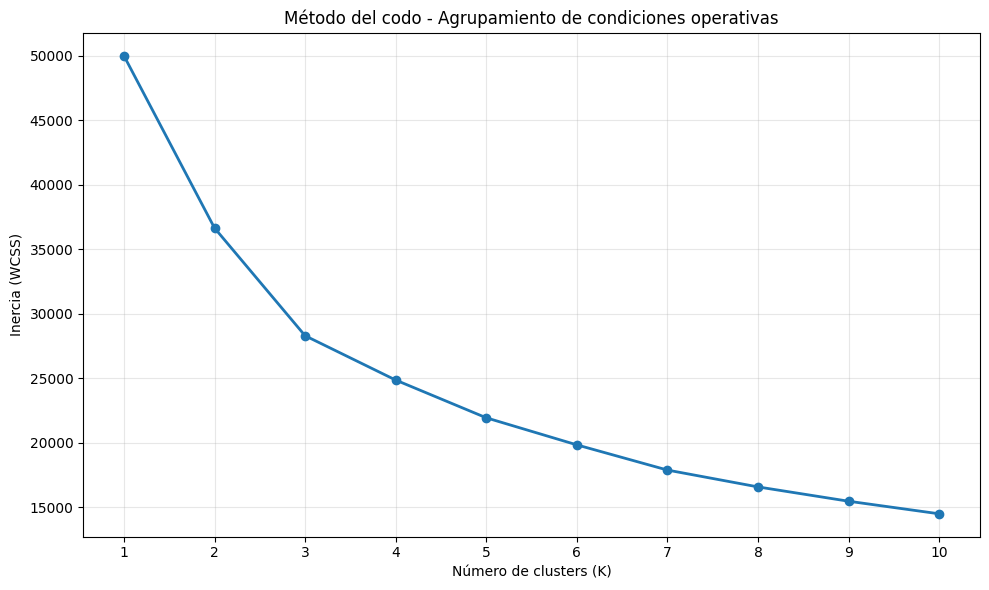

In [54]:
# 6.2 - Método del codo para K-Means


valores_k = range(1, 11)
inercias = []

for k in valores_k:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_clustering_scaled)

    inercias.append(kmeans.inertia_)

# Gráfico del método del codo
plt.figure(figsize=(10, 6))

plt.plot(
    list(valores_k),
    inercias,
    marker="o",
    linewidth=2
)

plt.xticks(list(valores_k))
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inercia (WCSS)")
plt.title("Método del codo - Agrupamiento de condiciones operativas")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 6.2.1. Interpretación del método del codo

Se aplicó el método del codo evaluando configuraciones de K-Means con valores de K entre 1 y 10.

Los resultados muestran una disminución pronunciada de la inercia durante las primeras configuraciones, especialmente entre K = 1 y K = 3.

A partir de tres clusters, la reducción de la inercia comienza a ser menos pronunciada, aunque continúa disminuyendo progresivamente al aumentar el número de grupos.

Este comportamiento sugiere que **K = 3 podría representar una cantidad razonable de clusters**, dado que permite capturar una parte importante de la reducción inicial de la variabilidad interna.

Sin embargo, el gráfico no presenta un punto de inflexión completamente inequívoco. Por este motivo, no se considera suficiente para determinar por sí solo la cantidad óptima de grupos.

En la siguiente etapa complementaremos el análisis mediante Silhouette Score, que permitirá estudiar tanto la cohesión interna de los clusters como su separación respecto de otros grupos.

La selección definitiva de K se realizará considerando ambas herramientas y la interpretabilidad de los agrupamientos obtenidos.

## 6.3. Evaluación de clusters mediante Silhouette Score

Para complementar el método del codo utilizaremos el coeficiente de silueta (*Silhouette Score*), una métrica que permite evaluar la calidad de los agrupamientos obtenidos.

Esta métrica considera dos aspectos:

- **Cohesión:** qué tan similares son las observaciones que pertenecen a un mismo cluster.
- **Separación:** qué tan diferentes son las observaciones respecto de los clusters vecinos.

El coeficiente de silueta toma valores entre -1 y 1:

- Valores cercanos a **1** indican observaciones bien agrupadas y separadas de otros clusters.
- Valores cercanos a **0** sugieren superposición o separación poco definida entre grupos.
- Valores negativos pueden indicar observaciones más cercanas a otro cluster que al asignado.

Evaluaremos configuraciones de K-Means entre 2 y 10 clusters, utilizando las variables operativas previamente estandarizadas.

Debido al tamaño del dataset, calcularemos el Silhouette Score sobre una muestra reproducible de observaciones, manteniendo el entrenamiento de K-Means sobre el conjunto completo.

Esta evaluación permitirá complementar la selección de K, aunque un valor elevado no garantiza que los clusters tengan una interpretación física o industrial relevante.

,K,Silhouette Score
0,2,0.2582
1,3,0.2590
2,4,0.2381
3,5,0.2243
4,6,0.2202
5,7,0.2280
6,8,0.2183
7,9,0.2147
8,10,0.2184


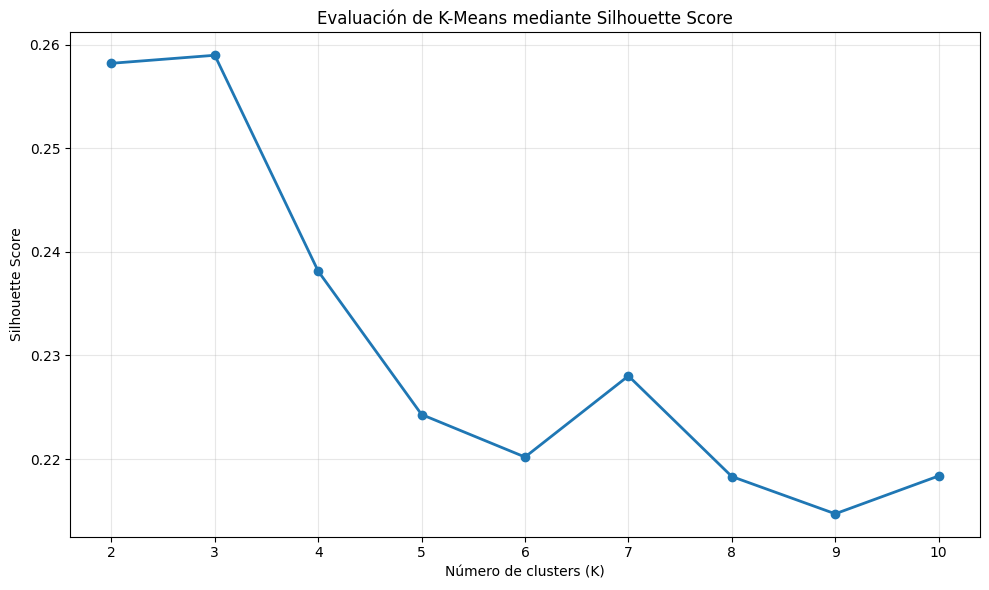

In [56]:
# 6.3 - Evaluación de K-Means mediante Silhouette Score



resultados_silueta = []

for k in range(2, 11):

    modelo_kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo_kmeans.fit_predict(
        X_clustering_scaled
    )

    puntuacion = silhouette_score(
        X_clustering_scaled,
        etiquetas,
        sample_size=3000,
        random_state=42
    )

    resultados_silueta.append({
        "K": k,
        "Silhouette Score": puntuacion
    })

tabla_silueta = pd.DataFrame(resultados_silueta)

display(tabla_silueta.round(4))

# Gráfico
plt.figure(figsize=(10, 6))

plt.plot(
    tabla_silueta["K"],
    tabla_silueta["Silhouette Score"],
    marker="o",
    linewidth=2
)

plt.xticks(range(2, 11))
plt.xlabel("Número de clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Evaluación de K-Means mediante Silhouette Score")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 6.3.1. Interpretación de los resultados de Silhouette Score

Se evaluaron diferentes configuraciones de K-Means, considerando valores de K entre 2 y 10.

El mayor Silhouette Score se obtuvo con **K = 3 (0,2590)**, seguido muy de cerca por K = 2 (0,2582).

Estos resultados son consistentes con el método del codo, que también sugería aproximadamente tres agrupamientos como una alternativa razonable.

Sin embargo, las puntuaciones obtenidas son relativamente bajas, lo que indica que los clusters presentan una separación limitada y posiblemente una superposición considerable.

Además, la diferencia entre las configuraciones de dos y tres clusters es mínima, por lo que no puede afirmarse que K = 3 sea claramente superior.

**Decisión metodológica:** se utilizarán tres clusters para continuar el análisis exploratorio, considerando conjuntamente el método del codo, Silhouette Score y la posibilidad de interpretar los perfiles operativos.

La elección de K = 3 no implica que existan exactamente tres grupos naturales bien definidos en el dataset.

En la siguiente sección analizaremos las características de los agrupamientos obtenidos y posteriormente estudiaremos si presentan diferencias en sus tasas de falla, sin utilizar las etiquetas de falla durante la construcción de los clusters.

### 6.3.1. Interpretación de los resultados de Silhouette Score

Se evaluaron diferentes configuraciones de K-Means, considerando valores de K entre 2 y 10.

El mayor Silhouette Score se obtuvo con **K = 3 (0,2590)**, seguido muy de cerca por K = 2 (0,2582).

Estos resultados son consistentes con el método del codo, que también sugería aproximadamente tres agrupamientos como una alternativa razonable.

Sin embargo, las puntuaciones obtenidas son relativamente bajas, lo que indica que los clusters presentan una separación limitada y posiblemente una superposición considerable.

Además, la diferencia entre las configuraciones de dos y tres clusters es mínima, por lo que no puede afirmarse que K = 3 sea claramente superior.

**Decisión metodológica:** se utilizarán tres clusters para continuar el análisis exploratorio, considerando conjuntamente el método del codo, Silhouette Score y la posibilidad de interpretar los perfiles operativos.

La elección de K = 3 no implica que existan exactamente tres grupos naturales bien definidos en el dataset.

En la siguiente sección analizaremos las características de los agrupamientos obtenidos y posteriormente estudiaremos si presentan diferencias en sus tasas de falla, sin utilizar las etiquetas de falla durante la construcción de los clusters.

,Cluster,Cantidad,Porcentaje
0,0,3930,39.30
1,1,4017,40.17
2,2,2053,20.53


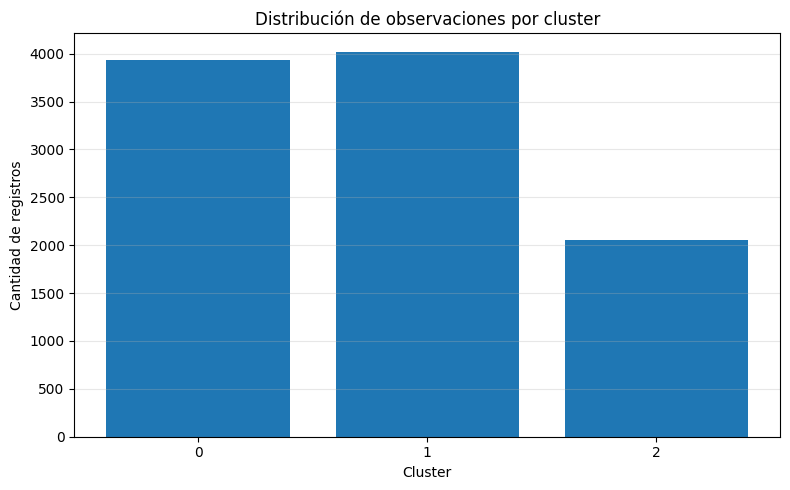

In [ ]:
# 6.4 - Aplicación de K-Means con K = 3
# Cantidad seleccionada de clusters
k_seleccionado = 3

# Modelo K-Means
modelo_kmeans_final = KMeans(
    n_clusters=k_seleccionado,
    random_state=42,
    n_init=10
)

# Entrenamiento y asignación de clusters
etiquetas_clusters = modelo_kmeans_final.fit_predict(
    X_clustering_scaled
)

# Copia para análisis de agrupamientos
df_clusters = df.copy()

df_clusters["Cluster"] = etiquetas_clusters

# Cantidad de observaciones por cluster
tabla_tamanos_clusters = (
    df_clusters["Cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Cantidad")
)

tabla_tamanos_clusters["Porcentaje"] = (
    tabla_tamanos_clusters["Cantidad"]
    / len(df_clusters) * 100
)

display(tabla_tamanos_clusters.round(2))

# Gráfico de distribución
plt.figure(figsize=(8, 5))

plt.bar(
    tabla_tamanos_clusters["Cluster"].astype(str),
    tabla_tamanos_clusters["Cantidad"]
)

plt.xlabel("Cluster")
plt.ylabel("Cantidad de registros")
plt.title("Distribución de observaciones por cluster")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 6.4.1. Interpretación de la distribución de clusters

Se aplicó K-Means con tres clusters sobre las cinco variables operativas originales previamente estandarizadas.

Los resultados muestran que los clusters 0 y 1 concentran aproximadamente el 40 % de las observaciones cada uno, mientras que el cluster 2 reúne alrededor del 20 % restante.

Esta distribución indica que el algoritmo identificó agrupamientos de tamaños diferentes, sin generar grupos extremadamente pequeños.

Sin embargo, la cantidad de observaciones asignadas a cada cluster no permite determinar por sí sola qué condiciones operativas los caracterizan ni si presentan diferencias en sus tasas de falla.

Además, los resultados previos de Silhouette Score sugieren una separación limitada entre los agrupamientos, por lo que estos deben interpretarse como una segmentación exploratoria y no como categorías industriales naturalmente definidas.

En la siguiente sección analizaremos los perfiles físicos de cada cluster mediante los valores promedio de las variables operativas utilizadas durante el agrupamiento.

## 6.5. Caracterización de los perfiles operativos

Una vez identificados los tres agrupamientos mediante K-Means, analizaremos las características físicas que distinguen a cada cluster.

Para ello calcularemos los valores promedio de las variables utilizadas durante el agrupamiento:

- Temperatura del aire.
- Temperatura del proceso.
- Velocidad de rotación.
- Torque.
- Desgaste de herramienta.

La comparación permitirá estudiar si los grupos representan diferentes condiciones operativas, como combinaciones de velocidad y torque o distintos niveles de temperatura y desgaste.

También construiremos un mapa de calor con los perfiles estandarizados de los clusters, facilitando la comparación de variables que originalmente poseen unidades y magnitudes diferentes.

En esta etapa no utilizaremos `Machine_failure` para caracterizar los grupos. Su relación con las fallas se analizará posteriormente y por separado, evitando confundir las características que definieron los clusters con las etiquetas supervisadas.

Perfil operativo promedio por cluster:


,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min
Cluster,,,,,
0,301.72,311.25,1469.81,43.64,110.36
1,298.26,308.74,1474.14,43.26,104.62
2,300.12,310.10,1797.26,26.57,109.85


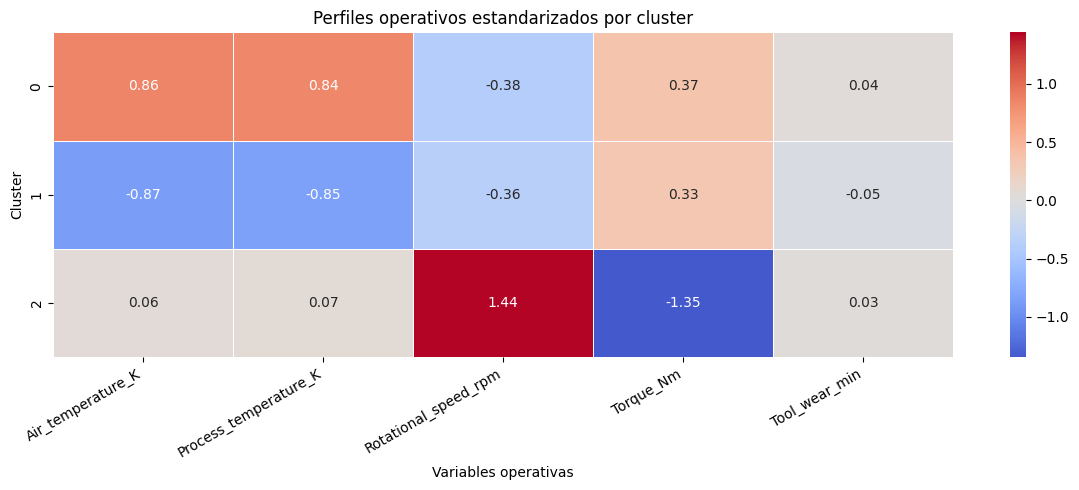

In [58]:
# 6.5 - Caracterización de los clusters
# Promedios de variables físicas por cluster
perfil_clusters = (
    df_clusters
    .groupby("Cluster")[variables_clustering]
    .mean()
)

print("Perfil operativo promedio por cluster:")
display(perfil_clusters.round(2))

# Perfiles en escala estandarizada
df_escalado_clusters = pd.DataFrame(
    X_clustering_scaled,
    columns=variables_clustering,
    index=df_clusters.index
)

df_escalado_clusters["Cluster"] = df_clusters["Cluster"]

perfil_estandarizado = (
    df_escalado_clusters
    .groupby("Cluster")[variables_clustering]
    .mean()
)

# Mapa de calor
plt.figure(figsize=(12, 5))

sns.heatmap(
    perfil_estandarizado,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Perfiles operativos estandarizados por cluster")
plt.xlabel("Variables operativas")
plt.ylabel("Cluster")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### 6.5.1. Interpretación de los perfiles operativos

La caracterización de los tres clusters permitió identificar diferencias en las condiciones térmicas y mecánicas de funcionamiento.

**Cluster 0 — Temperaturas elevadas:** presenta temperaturas del aire y del proceso superiores a la media general, con promedios de 301,72 K y 311,25 K, respectivamente. Su velocidad de rotación promedio es de 1.469,81 rpm y el torque alcanza 43,64 Nm.

**Cluster 1 — Temperaturas reducidas:** presenta temperaturas inferiores a la media, con valores promedio de 298,26 K para el aire y 308,74 K para el proceso. Sus condiciones de velocidad y torque son similares a las del cluster 0, por lo que la principal diferencia entre ambos agrupamientos es térmica.

**Cluster 2 — Alta velocidad y bajo torque:** presenta una velocidad promedio de 1.797,26 rpm y un torque promedio de 26,57 Nm. En el mapa de calor estandarizado, estas variables alcanzan valores de +1,44 y −1,35 desviaciones estándar, respectivamente, destacándose como las características que más diferencian este grupo.

El desgaste de herramienta presenta valores relativamente similares entre los tres clusters, por lo que no constituye una característica claramente diferenciadora de estos agrupamientos.

**Interpretación general:** K-Means identificó perfiles operativos asociados principalmente a diferencias de temperatura y a la relación entre velocidad de rotación y torque.

Sin embargo, debido al Silhouette Score relativamente bajo (0,2590), estos perfiles deben interpretarse como agrupamientos exploratorios con separación limitada y no como categorías industriales naturalmente definidas.

En la siguiente sección analizaremos si los clusters presentan diferentes tasas de falla, utilizando `Machine_failure` exclusivamente para interpretar los grupos ya construidos.

## 6.6. Análisis de tasas de falla por cluster

Una vez identificados y caracterizados los tres perfiles operativos, analizaremos su relación con la presencia de fallas.

Para ello, utilizaremos la variable `Machine_failure` únicamente después de haber construido los agrupamientos mediante K-Means.

Calcularemos para cada cluster:

- La cantidad total de observaciones.
- La cantidad de registros con falla.
- La tasa de falla porcentual.
- La relación entre su tasa de falla y la tasa general del dataset.

Este análisis permitirá investigar si determinadas condiciones operativas presentan una mayor frecuencia relativa de fallas.

También construiremos un gráfico comparativo que facilite la identificación de posibles diferencias entre los agrupamientos.

Es importante destacar que los clusters fueron obtenidos sin utilizar las etiquetas de falla y que las diferencias observadas no deben interpretarse como relaciones causales ni como evidencia de capacidad predictiva validada.

Debido a la separación limitada de los clusters, los resultados se considerarán exploratorios.

Tasa general de fallas: 3.39%


,Cluster,Registros,Fallas,Tasa_falla,Tasa_falla_pct,Riesgo_relativo_descriptivo
0,0,3930,206,0.052,5.242,1.546
1,1,4017,87,0.022,2.166,0.639
2,2,2053,46,0.022,2.241,0.661


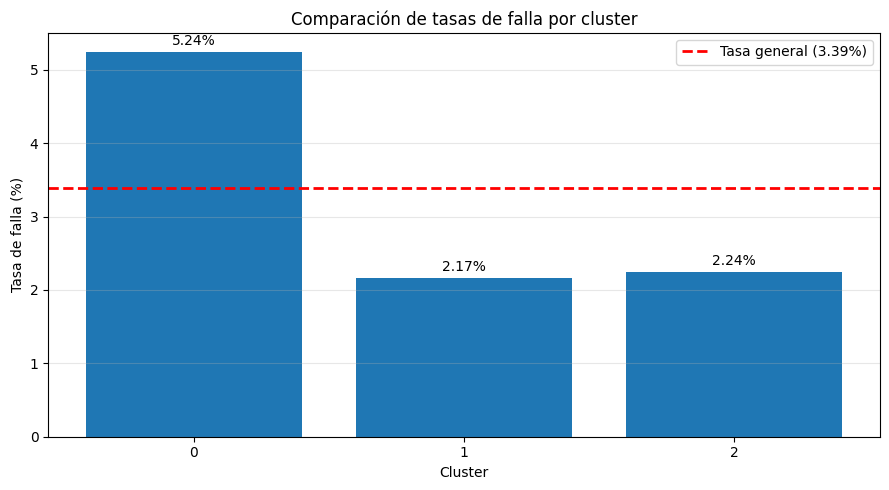

In [59]:
# 6.6 - Análisis de tasas de falla por cluster
# Resumen de fallas por cluster
tabla_fallas_clusters = (
    df_clusters
    .groupby("Cluster")["Machine_failure"]
    .agg(
        Registros="count",
        Fallas="sum",
        Tasa_falla="mean"
    )
    .reset_index()
)

# Convertir las tasas a porcentajes
tabla_fallas_clusters["Tasa_falla_pct"] = (
    tabla_fallas_clusters["Tasa_falla"] * 100
)

# Tasa general del dataset
tasa_general = df_clusters["Machine_failure"].mean() * 100

# Relación respecto de la tasa general
tabla_fallas_clusters["Riesgo_relativo_descriptivo"] = (
    tabla_fallas_clusters["Tasa_falla_pct"] / tasa_general
)

print(f"Tasa general de fallas: {tasa_general:.2f}%")

display(tabla_fallas_clusters.round(3))

# Visualización
fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.bar(
    tabla_fallas_clusters["Cluster"].astype(str),
    tabla_fallas_clusters["Tasa_falla_pct"]
)

ax.axhline(
    tasa_general,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Tasa general ({tasa_general:.2f}%)"
)

ax.bar_label(
    barras,
    fmt="%.2f%%",
    padding=3
)

ax.set_xlabel("Cluster")
ax.set_ylabel("Tasa de falla (%)")
ax.set_title("Comparación de tasas de falla por cluster")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 6.6.1. Interpretación de las tasas de falla por cluster

Se analizaron las tasas de falla de los tres agrupamientos identificados mediante K-Means, utilizando `Machine_failure` exclusivamente para interpretar los clusters una vez construidos.

Los resultados mostraron diferencias en la frecuencia relativa de fallas entre los grupos.

**Cluster 0 — Temperaturas elevadas:** presentó la mayor tasa de falla, con **206 fallas sobre 3.930 registros (5,24 %)**. Este valor representa aproximadamente 1,55 veces la tasa general del dataset (3,39 %). Además, concentra alrededor del 60,8 % de todas las fallas registradas.

**Cluster 1 — Temperaturas reducidas:** registró 87 fallas sobre 4.017 observaciones, con una tasa del 2,17 %, inferior a la general.

**Cluster 2 — Alta velocidad y bajo torque:** presentó 46 fallas sobre 2.053 observaciones, con una tasa del 2,24 %, también inferior a la general.

Estos resultados indican que los perfiles operativos identificados mediante aprendizaje no supervisado presentan diferencias descriptivas en sus tasas de falla.

En particular, el cluster caracterizado por temperaturas más elevadas presenta una frecuencia relativa de fallas superior a la observada en los otros dos grupos.

Sin embargo, esta asociación no demuestra que las temperaturas sean la causa de las fallas. Las diferencias también podrían estar relacionadas con otras condiciones operativas o con los mecanismos utilizados para generar el dataset sintético.

**Implicancias para el proyecto:** el análisis demuestra que K-Means permite construir perfiles operativos interpretables y explorar sus asociaciones con la presencia de fallas, incluso sin utilizar la variable objetivo durante el agrupamiento.

No obstante, el Silhouette Score relativamente bajo indica que los grupos presentan una separación limitada. Por lo tanto, estos resultados no permiten afirmar que existan tres categorías naturales claramente diferenciadas ni que los clusters constituyan un sistema predictivo validado.

## 6.7. Conclusiones generales del aprendizaje no supervisado

Se aplicó el algoritmo K-Means para investigar si las condiciones operativas del dataset AI4I 2020 presentan agrupamientos identificables sin utilizar las etiquetas de falla durante el entrenamiento.

A partir del método del codo y Silhouette Score, se seleccionó una configuración exploratoria de tres clusters.

El Silhouette Score obtenido para K = 3 fue de **0,2590**, indicando que los grupos presentan una separación relativamente limitada. Por lo tanto, los resultados deben interpretarse como una segmentación exploratoria y no como evidencia de tres grupos naturales claramente definidos.

La caracterización de los clusters permitió identificar tres perfiles:

1. **Cluster 0:** condiciones de temperaturas relativamente elevadas, velocidad moderadamente baja y torque ligeramente superior al promedio.
2. **Cluster 1:** condiciones de temperaturas relativamente reducidas, con velocidades y torques similares a los del cluster 0.
3. **Cluster 2:** condiciones de velocidad elevada y torque reducido, con temperaturas cercanas al promedio general.

Posteriormente, el análisis de las tasas de falla mostró que el cluster 0 presenta la mayor frecuencia relativa de fallas (5,24 %), frente al 2,17 % del cluster 1 y el 2,24 % del cluster 2.

Este resultado sugiere que determinados perfiles operativos están asociados con diferentes frecuencias de falla, aunque no permite establecer relaciones causales.

**Aporte al proyecto:** el aprendizaje no supervisado permitió complementar el análisis predictivo mediante una exploración de la estructura de las condiciones operativas, aportando una perspectiva diferente de la clasificación supervisada.

Sin embargo, los clusters no se incorporarán al modelo final, debido a que no se ha demostrado que mejoren su capacidad predictiva y a que su construcción se realizó como un análisis exploratorio independiente.

En consecuencia, K-Means se presenta como una herramienta complementaria para caracterizar condiciones operativas, no como un sustituto del modelo supervisado de detección de fallas.

# 7. Interpretabilidad del modelo supervisado

Después de desarrollar y evaluar el modelo Random Forest, resulta importante analizar qué características operativas tienen mayor influencia sobre sus predicciones.

La interpretabilidad permite comprender mejor el comportamiento del clasificador, relacionar sus resultados con las hipótesis físicas desarrolladas durante el EDA e identificar posibles dependencias entre variables.

Para ello utilizaremos técnicas de explicabilidad posteriores al entrenamiento (*post-hoc*), comenzando con **Permutation Importance**.

## 7.1. Importancia de características mediante Permutation Importance

Permutation Importance mide la disminución del rendimiento predictivo cuando los valores de una característica se mezclan aleatoriamente entre las observaciones.

Si alterar una variable provoca una caída importante en el rendimiento, se considera que dicha característica tiene una contribución relevante para el modelo bajo las condiciones evaluadas.

Utilizaremos Average Precision como métrica de referencia, manteniendo la coherencia con el criterio principal empleado durante la optimización de hiperparámetros.

Este análisis se realizará sobre el conjunto de desarrollo mediante predicciones de validación cruzada, evitando reutilizar el conjunto de prueba final para nuevas decisiones de modelado.

También tendremos en cuenta que algunas características están altamente correlacionadas. En esos casos, Permutation Importance puede subestimar la contribución de una variable porque otras características contienen información similar.

Finalmente, los resultados se interpretarán como medidas de dependencia predictiva del modelo y no como evidencia de relaciones causales entre las condiciones operativas y las fallas.

,Variable,Importancia_media,Desviacion_estandar
0,Rotational_speed_rpm,0.2979,0.0419
1,Mechanical_power_W,0.2653,0.0561
2,Temperature_difference_K,0.2349,0.0426
3,Tool_wear_min,0.2240,0.0424
4,Torque_Nm,0.0662,0.0189
5,Type,0.0157,0.0043
6,Air_temperature_K,0.0062,0.0064
7,Process_temperature_K,0.0031,0.0063


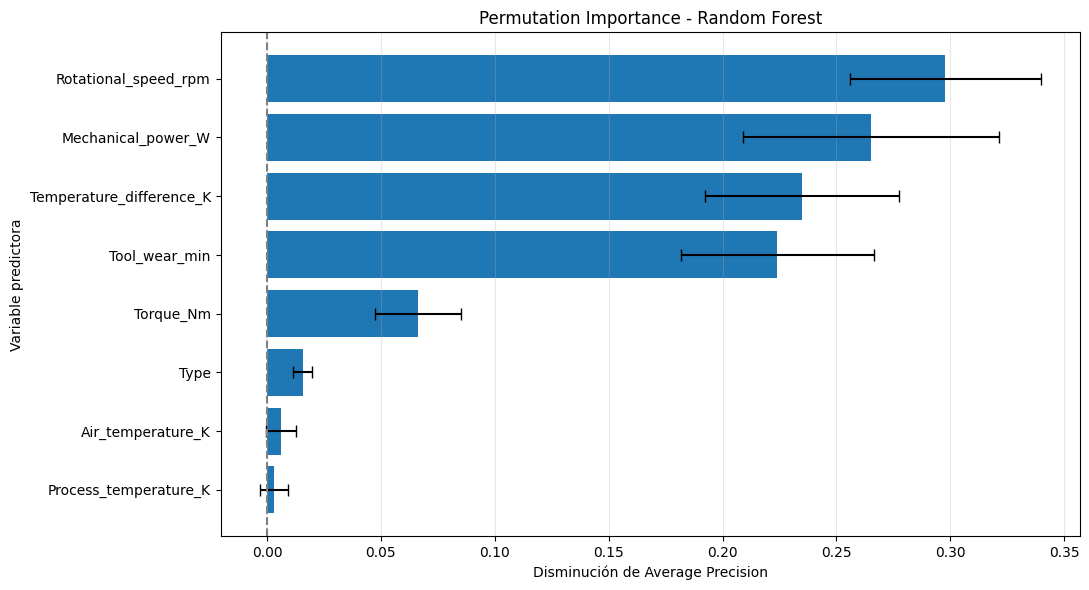

In [60]:
# 7.1 - Permutation Importance mediante validación cruzada


# Guardar las importancias de cada partición
importancias_folds = []

for fold, (idx_train, idx_val) in enumerate(
    cv_externa.split(X_train, y_train), start=1
):

    X_ent = X_train.iloc[idx_train]
    X_val = X_train.iloc[idx_val]

    y_ent = y_train.iloc[idx_train]
    y_val = y_train.iloc[idx_val]

    # Crear una copia independiente del modelo final
    modelo_fold = clone(modelo_final_rf)

    # Entrenar solamente con los registros del fold
    modelo_fold.fit(X_ent, y_ent)

    # Calcular importancia sobre la validación
    resultado = permutation_importance(
        modelo_fold,
        X_val,
        y_val,
        scoring="average_precision",
        n_repeats=5,
        random_state=42,
        n_jobs=-1
    )

    importancias_folds.append(resultado.importances_mean)

# Convertir los resultados a DataFrame
df_importancias = pd.DataFrame(
    importancias_folds,
    columns=X_train.columns
)

# Promedio y desviación estándar entre folds
tabla_importancias = pd.DataFrame({
    "Variable": X_train.columns,
    "Importancia_media": df_importancias.mean().values,
    "Desviacion_estandar": df_importancias.std().values
})

tabla_importancias = tabla_importancias.sort_values(
    "Importancia_media",
    ascending=False
).reset_index(drop=True)

display(tabla_importancias.round(4))

# Gráfico horizontal
plt.figure(figsize=(11, 6))

plt.barh(
    tabla_importancias["Variable"],
    tabla_importancias["Importancia_media"],
    xerr=tabla_importancias["Desviacion_estandar"],
    capsize=4
)

plt.axvline(0, color="gray", linestyle="--")

plt.xlabel("Disminución de Average Precision")
plt.ylabel("Variable predictora")
plt.title("Permutation Importance - Random Forest")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### 7.1.1. Interpretación de los resultados de Permutation Importance

Se aplicó Permutation Importance al modelo Random Forest utilizando validación cruzada sobre el conjunto de desarrollo y Average Precision como métrica de referencia.

Los resultados mostraron que las características con mayor importancia predictiva fueron:

- `Rotational_speed_rpm`: importancia media de 0,2979.
- `Mechanical_power_W`: importancia media de 0,2653.
- `Temperature_difference_K`: importancia media de 0,2349.
- `Tool_wear_min`: importancia media de 0,2240.

Estas variables produjeron las mayores disminuciones de Average Precision cuando sus valores fueron permutados, lo que indica una dependencia relevante del clasificador respecto de ellas.

En particular, las dos características derivadas mediante ingeniería de características se ubicaron entre las tres variables más importantes.

Este resultado es coherente con el estudio de ablación, donde la incorporación de ambas características mejoró el rendimiento del modelo respecto del conjunto de variables originales.

Por otra parte, `Torque_Nm`, `Type` y las temperaturas originales presentaron importancias individuales inferiores.

Sin embargo, estas diferencias deben interpretarse con cautela debido a las correlaciones existentes entre las características.

Por ejemplo, la potencia mecánica se calcula a partir del torque y la velocidad de rotación, mientras que la diferencia térmica depende de las temperaturas originales. Por lo tanto, parte de la información puede encontrarse representada en múltiples variables.

Además, la permutación independiente puede generar combinaciones de características que no respeten las relaciones físicas originales.

**Implicancias para el proyecto:** los resultados respaldan la utilidad predictiva de las características derivadas y muestran que Random Forest utiliza principalmente información relacionada con las condiciones mecánicas, el desgaste y las diferencias térmicas.

No obstante, Permutation Importance mide dependencia predictiva bajo las condiciones evaluadas y no permite establecer relaciones causales ni determinar qué variables provocan físicamente las fallas.

## 7.2. Explicabilidad global mediante SHAP

Para profundizar la interpretación de Random Forest utilizaremos **SHAP (SHapley Additive exPlanations)**, una técnica basada en valores de Shapley que permite descomponer las predicciones del modelo en contribuciones atribuidas a sus características.

A diferencia de Permutation Importance, que mide cuánto disminuye el rendimiento al alterar una variable, SHAP analiza las contribuciones de las características a las predicciones del modelo respecto de un valor de referencia.

Utilizaremos `TreeExplainer`, una implementación de SHAP especializada en modelos basados en árboles.

El análisis se realizará sobre una muestra reproducible de observaciones del conjunto de desarrollo, utilizando el modelo Random Forest previamente entrenado.

Dado que el modelo incluye un pipeline de preprocesamiento, primero transformaremos los datos mediante el `ColumnTransformer` ya ajustado y posteriormente calcularemos los valores SHAP del clasificador.

Nos concentraremos en las contribuciones correspondientes a la **clase positiva (`Machine_failure = 1`)**.

Los resultados se representarán mediante:

- **Gráfico de importancia global:** mostrará la magnitud media absoluta de las contribuciones SHAP.
- **Gráfico resumen (beeswarm):** permitirá observar cómo se distribuyen las contribuciones positivas y negativas de cada característica entre las observaciones analizadas.

Este análisis complementará los resultados del EDA, el estudio de ablación y Permutation Importance.

Es importante destacar que SHAP explica el comportamiento del modelo bajo determinados supuestos sobre las características, pero no establece relaciones causales entre las condiciones operativas y las fallas.

In [62]:
print("Versión de SHAP:", shap.__version__)

Versión de SHAP: 0.54.1


c:\Users\Asus\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dimensiones de los datos: (200, 10)
Dimensiones SHAP: (200, 10)


,Variable,Importancia_SHAP
7,numericas__Tool_wear_min,0.0280
5,numericas__Rotational_speed_rpm,0.0208
9,numericas__Mechanical_power_W,0.0177
6,numericas__Torque_Nm,0.0173
8,numericas__Temperature_difference_K,0.0167
3,numericas__Air_temperature_K,0.0063
4,numericas__Process_temperature_K,0.0029
1,categoricas__Type_L,0.0020
2,categoricas__Type_M,0.0010
0,categoricas__Type_H,0.0003


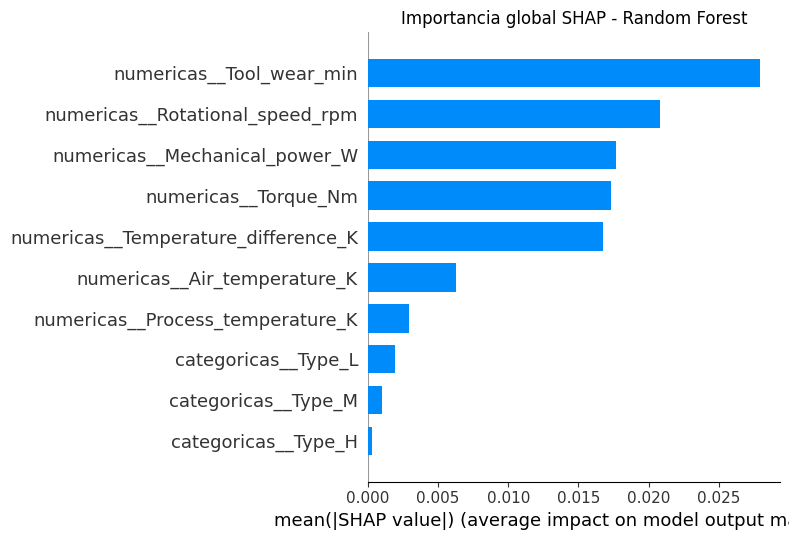

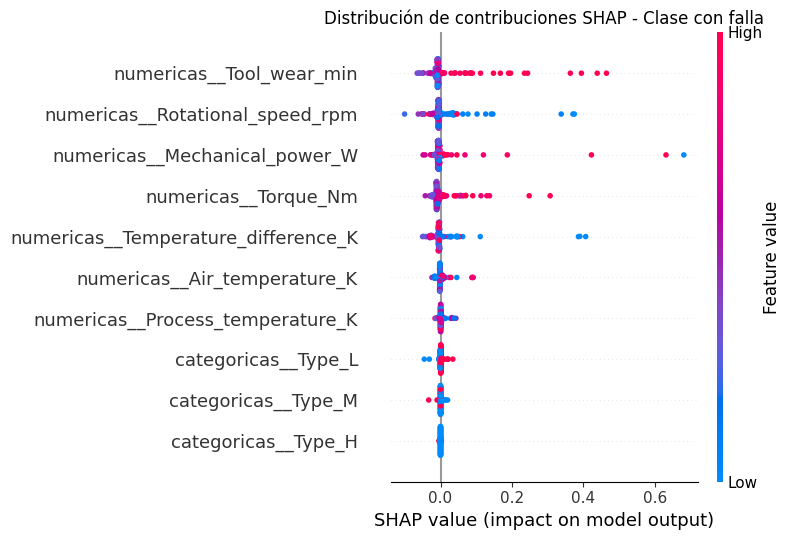

In [63]:
# 7.2 - Explicabilidad global mediante SHAP



# Muestra reproducible del conjunto de desarrollo
X_shap = X_train.sample(
    n=min(200, len(X_train)),
    random_state=42
).copy()

# Recuperar los componentes del pipeline entrenado
preprocesador_shap = modelo_final_rf.named_steps["preprocesamiento"]
clasificador_shap = modelo_final_rf.named_steps["modelo"]

# Transformar sin volver a ajustar el preprocesador
X_shap_transformado = preprocesador_shap.transform(X_shap)

if hasattr(X_shap_transformado, "toarray"):
    X_shap_transformado = X_shap_transformado.toarray()

# Recuperar nombres de las características transformadas
nombres_shap = preprocesador_shap.get_feature_names_out()

X_shap_df = pd.DataFrame(
    X_shap_transformado,
    columns=nombres_shap,
    index=X_shap.index
)

# Explicador para Random Forest
explainer_shap = shap.TreeExplainer(
    clasificador_shap,
    feature_perturbation="tree_path_dependent"
)

# Calcular contribuciones
valores_shap_raw = explainer_shap.shap_values(X_shap_df)

# Seleccionar la clase positiva
if isinstance(valores_shap_raw, list):
    valores_shap_positivos = valores_shap_raw[1]
else:
    valores_shap_raw = np.asarray(valores_shap_raw)

    if valores_shap_raw.ndim == 3:
        valores_shap_positivos = valores_shap_raw[:, :, 1]
    elif valores_shap_raw.ndim == 2:
        valores_shap_positivos = valores_shap_raw
    else:
        raise ValueError("Formato SHAP no reconocido")

assert valores_shap_positivos.shape == X_shap_df.shape

print("Dimensiones de los datos:", X_shap_df.shape)
print("Dimensiones SHAP:", valores_shap_positivos.shape)

# Importancia global: media del valor absoluto de SHAP
tabla_shap = pd.DataFrame({
    "Variable": nombres_shap,
    "Importancia_SHAP": np.abs(
        valores_shap_positivos
    ).mean(axis=0)
})

tabla_shap = tabla_shap.sort_values(
    "Importancia_SHAP",
    ascending=False
)

display(tabla_shap.round(4))

# Gráfico de importancia global
shap.summary_plot(
    valores_shap_positivos,
    X_shap_df,
    plot_type="bar",
    show=False
)

plt.title("Importancia global SHAP - Random Forest")
plt.tight_layout()
plt.show()

# Gráfico resumen de contribuciones
shap.summary_plot(
    valores_shap_positivos,
    X_shap_df,
    show=False
)

plt.title("Distribución de contribuciones SHAP - Clase con falla")
plt.tight_layout()
plt.show()

### 7.2.1. Conclusiones del análisis global mediante SHAP

Se aplicó SHAP mediante `TreeExplainer` para analizar las contribuciones de las características a las predicciones de Random Forest correspondientes a la clase positiva (`Machine_failure = 1`).

El análisis se realizó sobre una muestra reproducible de 200 observaciones del conjunto de desarrollo, previamente transformadas mediante el pipeline entrenado.

Los resultados mostraron que las características con mayor magnitud media absoluta de contribución SHAP fueron:

- `Tool_wear_min`: 0,0280.
- `Rotational_speed_rpm`: 0,0208.
- `Mechanical_power_W`: 0,0177.
- `Torque_Nm`: 0,0173.
- `Temperature_difference_K`: 0,0167.

El gráfico de distribución permitió observar que determinados valores elevados de desgaste, torque y potencia mecánica presentan contribuciones positivas relevantes para la clasificación de registros con falla.

También se identificaron contribuciones positivas asociadas con determinadas velocidades de rotación reducidas y diferencias térmicas bajas.

Estos patrones son compatibles con las relaciones mecánicas y térmicas investigadas previamente durante el análisis exploratorio.

### Comparación con Permutation Importance

Ambas técnicas destacaron la relevancia de las variables mecánicas y de las características derivadas, aunque presentaron diferencias en su orden de importancia.

En particular, `Tool_wear_min` ocupó el primer lugar en SHAP, mientras que `Rotational_speed_rpm` obtuvo la mayor importancia mediante Permutation Importance.

Esta diferencia se explica por los distintos criterios utilizados: SHAP atribuye contribuciones a las salidas del modelo, mientras que Permutation Importance mide la disminución del rendimiento predictivo al alterar una característica.

**Implicancias para el proyecto:** los resultados complementan el estudio de ablación y respaldan la utilidad de las características derivadas en el comportamiento predictivo de Random Forest.

Sin embargo, la presencia de correlaciones y relaciones matemáticas entre variables puede afectar la distribución de las contribuciones. Además, el análisis se realizó sobre una muestra de 200 observaciones.

Por lo tanto, los resultados deben interpretarse como explicaciones estadísticas del comportamiento del modelo, sin atribuir causalidad a las características estudiadas.

## 7.3. Interpretación de predicciones individuales mediante SHAP

Una vez identificadas las características más relevantes a nivel global, analizaremos cómo contribuyen las variables operativas a la predicción de una observación individual.

Utilizaremos un gráfico SHAP de tipo *waterfall*, que representa las contribuciones de las características desde un valor de referencia hasta la salida estimada por el modelo.

El objetivo será identificar qué condiciones operativas contribuyen a aumentar o disminuir la salida correspondiente a la clase positiva.

El análisis se realizará sobre una observación del conjunto de desarrollo, sin utilizar el conjunto de prueba final para seleccionar casos.

Las contribuciones se interpretarán como explicaciones del comportamiento estadístico de Random Forest, sin considerarlas mecanismos causales de falla.

c:\Users\Asus\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


Probabilidad estimada: 0.0
Salida reconstruida con SHAP: 0.0


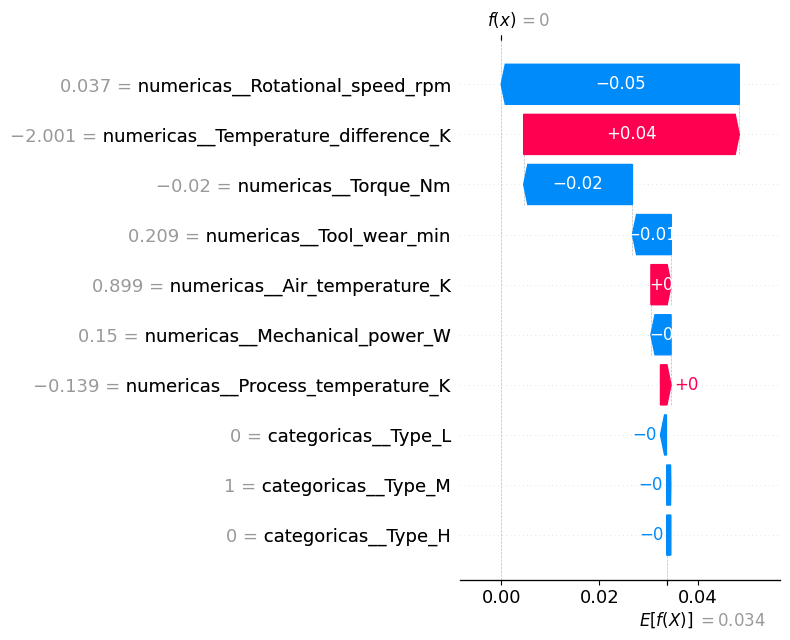

In [64]:
# 7.3 - Explicación individual con SHAP


# Primera observación de la muestra
indice_observacion = 0

# Valor de referencia para la clase positiva
valor_base = np.asarray(explainer_shap.expected_value)

if valor_base.ndim == 0:
    base_positivo = float(valor_base)
else:
    base_positivo = float(valor_base.ravel()[1])

# Construir explicación individual
explicacion_individual = shap.Explanation(
    values=valores_shap_positivos[indice_observacion],
    base_values=base_positivo,
    data=X_shap_df.iloc[indice_observacion].values,
    feature_names=X_shap_df.columns.tolist()
)

# Verificar reconstrucción de la salida del modelo
probabilidad_modelo = clasificador_shap.predict_proba(
    X_shap_df.iloc[[indice_observacion]]
)[0, 1]

salida_reconstruida = (
    base_positivo
    + valores_shap_positivos[indice_observacion].sum()
)

print("Probabilidad estimada:", round(probabilidad_modelo, 4))
print("Salida reconstruida con SHAP:", round(salida_reconstruida, 4))

# Gráfico individual
shap.plots.waterfall(
    explicacion_individual,
    max_display=10,
    show=False
)

plt.tight_layout()
plt.show()

### 7.3.1. Interpretación de una observación con baja probabilidad de falla

Se utilizó SHAP para analizar las contribuciones individuales de las características operativas a una predicción de Random Forest.

La observación seleccionada presentó una salida estimada prácticamente nula para la clase positiva, por debajo del umbral de clasificación establecido en 0,37.

El gráfico *waterfall* permitió identificar las contribuciones que llevaron al modelo desde su valor de referencia, aproximadamente 0,034, hasta la predicción individual.

La velocidad de rotación y el torque presentaron contribuciones negativas relevantes, reduciendo la salida estimada para la clase con falla.

Por el contrario, la diferencia de temperaturas presentó una contribución positiva, aunque insuficiente para compensar el efecto conjunto de las variables que redujeron la predicción.

Este resultado demuestra que el modelo considera simultáneamente múltiples condiciones operativas y que una característica con contribución positiva no implica necesariamente una predicción de falla.

**Implicancias para el proyecto:** SHAP permite interpretar qué características influyen sobre una predicción particular y en qué dirección lo hacen.

Sin embargo, las contribuciones explican el comportamiento estadístico del modelo y no representan efectos causales sobre el funcionamiento de la máquina.

### 7.3.2. Interpretación de una observación con alta probabilidad de falla

Para complementar la explicación anterior, analizaremos una observación a la que Random Forest asigne una probabilidad elevada de pertenecer a la clase con falla.

Se seleccionará el registro con mayor probabilidad estimada dentro de la muestra utilizada para el análisis SHAP.

Mediante un segundo gráfico *waterfall*, identificaremos las características que contribuyen a aumentar o disminuir la salida estimada.

El objetivo será comparar las explicaciones individuales de una observación con baja probabilidad de falla y otra con alta probabilidad.

Esta comparación permitirá mostrar cómo distintas combinaciones de condiciones operativas producen predicciones diferentes.

El registro se seleccionará únicamente con fines ilustrativos y no se utilizará para evaluar ni modificar el modelo.

Probabilidad estimada: 0.9944
Reconstrucción SHAP: 0.9944
Diferencia absoluta: 0.0
Clasificación: Con falla

Características operativas originales:


c:\Users\Asus\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


,Type,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Temperature_difference_K,Mechanical_power_W
4417,L,302.6,310.4,1365,66.8,80,7.8,9548.556711


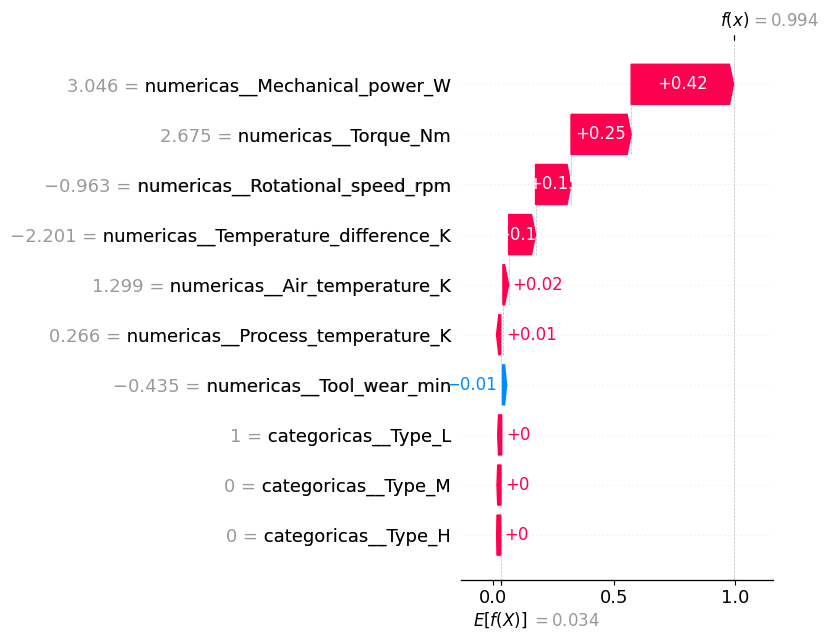

In [65]:
# 7.3.2 - Explicación SHAP de una observación de alto riesgo

# Probabilidades estimadas para la muestra SHAP
probabilidades_muestra = clasificador_shap.predict_proba(
    X_shap_df
)[:, 1]

# Seleccionar la observación con mayor probabilidad
indice_alto_riesgo = int(
    np.argmax(probabilidades_muestra)
)

probabilidad_alta = float(
    probabilidades_muestra[indice_alto_riesgo]
)

# Explicación SHAP de la clase positiva
explicacion_alto_riesgo = shap.Explanation(
    values=valores_shap_positivos[indice_alto_riesgo],
    base_values=base_positivo,
    data=X_shap_df.iloc[indice_alto_riesgo].values,
    feature_names=X_shap_df.columns.tolist()
)

# Verificación de reconstrucción
salida_shap = (
    base_positivo
    + valores_shap_positivos[indice_alto_riesgo].sum()
)

print("Probabilidad estimada:", round(probabilidad_alta, 4))
print("Reconstrucción SHAP:", round(salida_shap, 4))
print("Diferencia absoluta:", round(
    abs(probabilidad_alta - salida_shap), 8
))

print(
    "Clasificación:",
    "Con falla" if probabilidad_alta >= umbral_final_rf
    else "Sin falla"
)

print("\nCaracterísticas operativas originales:")
display(X_shap.iloc[[indice_alto_riesgo]])

# Gráfico waterfall
shap.plots.waterfall(
    explicacion_alto_riesgo,
    max_display=10,
    show=False
)

plt.tight_layout()
plt.show()

#### Conclusiones de la predicción individual de alta probabilidad

Se utilizó SHAP para interpretar una observación del conjunto de desarrollo a la que Random Forest asignó una salida estimada de aproximadamente **0,994 para la clase positiva**, considerablemente superior al umbral de clasificación establecido en 0,37.

El registro presentó una velocidad de rotación de 1.365 rpm, un torque de 66,8 Nm y una potencia mecánica aproximada de 9.548,56 W.

El gráfico waterfall mostró que las principales contribuciones positivas correspondieron a:

- **Potencia mecánica:** contribución aproximada de +0,42.
- **Torque:** contribución aproximada de +0,25.
- **Velocidad de rotación y diferencia térmica:** contribuciones positivas adicionales.

Estas características elevaron considerablemente la salida del modelo respecto de su valor de referencia, cercano a 0,034.

Al comparar este resultado con la observación de baja probabilidad analizada anteriormente, se evidencia que distintas combinaciones de características operativas pueden producir predicciones muy diferentes.

**Implicancias para el proyecto:** el análisis permite interpretar cómo Random Forest utiliza las relaciones entre variables mecánicas y térmicas para clasificar registros.

No obstante, la observación fue seleccionada intencionalmente por presentar la mayor probabilidad estimada dentro de la muestra utilizada para SHAP. Por lo tanto, constituye un ejemplo ilustrativo y no representa necesariamente el comportamiento habitual del modelo.

Además, las explicaciones corresponden al comportamiento aprendido por el clasificador y no permiten establecer relaciones causales entre las condiciones operativas y las fallas.

## 7.4. Conclusiones generales de interpretabilidad

Se aplicaron dos técnicas complementarias de interpretabilidad, Permutation Importance y SHAP, con el objetivo de comprender qué características operativas utiliza Random Forest para realizar sus predicciones.

### Importancia global de las variables

Permutation Importance identificó como características más relevantes la velocidad de rotación, la potencia mecánica, la diferencia térmica y el desgaste de herramienta.

Por su parte, SHAP destacó principalmente el desgaste, la velocidad de rotación, la potencia mecánica, el torque y la diferencia de temperaturas.

Aunque ambos métodos presentaron diferencias en el orden de importancia, coincidieron en señalar la relevancia predictiva de las condiciones mecánicas y de las características derivadas.

Estos resultados complementan los experimentos de ablación, donde se observó que la incorporación de `Temperature_difference_K` y `Mechanical_power_W` mejoró el desempeño del modelo.

### Interpretabilidad individual

Se analizaron dos observaciones mediante gráficos SHAP waterfall.

La primera presentó una salida estimada prácticamente nula para la clase positiva, mientras que la segunda alcanzó aproximadamente 0,994.

En la observación de alta probabilidad, las principales contribuciones positivas provinieron de la potencia mecánica y el torque, mostrando la relevancia de determinadas combinaciones de condiciones operativas.

Estos ejemplos permiten ilustrar cómo el modelo combina diferentes características para producir una clasificación.

### Limitaciones

Las técnicas utilizadas explican el comportamiento estadístico del modelo, pero no permiten demostrar relaciones causales.

Asimismo, las correlaciones entre variables originales y derivadas pueden afectar la distribución de las contribuciones.

El análisis SHAP se realizó sobre una muestra de 200 observaciones del conjunto de desarrollo y los casos individuales fueron seleccionados con fines ilustrativos.

### Aporte al proyecto

La incorporación de técnicas de interpretabilidad permitió complementar la evaluación predictiva con un análisis de las características que influyen sobre las decisiones de Random Forest.

Esto aporta transparencia al prototipo, facilita la comprensión de sus predicciones y permite relacionar sus resultados con las hipótesis físicas desarrolladas durante el análisis exploratorio.

Sin embargo, la interpretabilidad no sustituye la validación del modelo ni demuestra que sus explicaciones representen mecanismos físicos causales.